# 06 - Cross-Model Analysis

**IT469 (King Saud University) - NER on Human-Written vs. LLM-Generated News**

## Purpose

This notebook is the project's final analysis stage. It trains **nothing** -- it only reads the results
that `04_crf_baseline.ipynb` and the three `05_main_models-*.ipynb` notebooks already wrote to Drive, and
combines them into one cross-model picture: master tables across all 4 models, one joint paired bootstrap
over all 16 (model, trained, tested) combinations, CRF confusion matrices (the CRF notebook never built
these) plus side-by-side comparisons across models, the project's three research questions (RQ1-RQ3) each
answered from computed values, entity distributions per text source, a vocabulary mechanism check, example
error analysis, and a `report_assets/` folder of LaTeX tables and final figures for the report's Results
section.

## Models compared

| Tag | Display name | Source notebook |
|---|---|---|
| `bert-base-cased` | BERT-base | `05_main_models-bert-base-cased.ipynb` |
| `roberta-base` | RoBERTa-base | `05_main_models-roberta-base.ipynb` |
| `distilbert-base-cased` | DistilBERT-base | `05_main_models-distilbert-base-cased.ipynb` |
| `crf` | CRF baseline | `04_crf_baseline.ipynb` |

## What this notebook does NOT do

- It does not retrain or re-predict anything. If a required file is missing, Section 4 prints exactly
  what's missing and stops -- it never falls back to recomputing from raw data.
- It does not re-litigate the CRF's or any transformer's own 2x2/bootstrap results (notebooks 04/05); it
  reuses their saved numbers and adds a NEW joint bootstrap that spans all 4 models at once with one shared
  article resample, which none of the individual notebooks could do on their own.

## Limitation, stated plainly (repeated from notebooks 03-05, because it matters here most of all)

Every score anywhere in this notebook measures agreement with the **silver labels** from notebook 03, not
accuracy against human-annotated ground truth on these news articles -- there is no such ground truth for
this dataset. The annotator's own CoNLL-2003 test F1 (**0.9273**, `roberta-large`, selected in notebook 02)
is the only available proxy for how trustworthy those silver labels are, and therefore an implicit ceiling
on every comparison below. Each of the three transformer models was trained with a **single fixed seed**
(42) -- the numbers below are single runs, not a distribution over seeds, and the CRF has no seed-level
variance story at all (`lbfgs` is deterministic given its hyperparameters).

## Output layout

```
ROOT/results/analysis/
├── tables/            # master_2x2.csv, master_per_type_f1.csv, master_per_topic_f1.csv, joint_bootstrap.csv,
│                       # rq1_test_domain.csv, rq2_train_domain.csv, rq3_type_gap.csv, rq3_topic_gap.csv,
│                       # entity_vocab_coverage.csv, vocab_recall.csv, entity_counts.csv (copied), entity_stats.csv (copied)
├── figures/            # confusion_entity_norm_grid.png, confusion_token_norm_grid.png, rq1_*.png, rq2_*.png,
│                       # rq3_*.png, entity_distribution.png, vocab_recall.png, joint_bootstrap.png
├── confusion_matrices/ # crf_{token,entity}_{trained}_on_{tested}_{raw,norm}.csv (the transformers' own
│                       # confusion CSVs already exist under results/main/{tag}/confusion_matrices/ and are
│                       # read from there, not duplicated here)
├── error_examples/     # {model}_{trained}_on_{tested}.csv, a handful of example errors per category
└── report_assets/      # LaTeX-ready .tex table files + the final figures selected for the report
```

## How to run

1. **No GPU needed.** Edit nothing in most cases -- the Configuration cell (Section 1) only lists the 4
   models and a couple of constants that should not need to change.
2. Runtime > Run all. Section 4 prints a present/missing table for every input file this notebook needs
   from notebooks 02-05 and **stops with a clear error** if anything is missing (Drive listing glitches and
   manual deletions have bitten this project before -- see Stages 1/2 in `CLAUDE.md` -- so this notebook
   never assumes a file exists without checking first).
3. Everything else computes quickly (reading CSVs, one 1,000-iteration bootstrap over article-level counts,
   building figures) -- expect a couple of minutes total, no resumability logic needed.

## References

In-text citations `[1]`-`[9]` point to the numbered list in the last section of this notebook.


## 1. Configuration


In [1]:
# Configuration: the 4 models being compared, display names for the report, and the few constants this
# notebook needs. No SMOKE_TEST / FORCE_REBUILD switches -- this notebook is read-only and cheap to rerun
# in full every time.

MODEL_TAGS = ["bert-base-cased", "roberta-base", "distilbert-base-cased", "crf"]
MODEL_DISPLAY_NAMES = {
    "bert-base-cased": "BERT-base",
    "roberta-base": "RoBERTa-base",
    "distilbert-base-cased": "DistilBERT-base",
    "crf": "CRF baseline",
}
TRANSFORMER_TAGS = [t for t in MODEL_TAGS if t != "crf"]  # the 3 models with a grid-searched Trainer config

LABEL_NAMES = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC"]
ENTITY_TYPES = ["PER", "ORG", "LOC", "MISC"]

SEED = 42
N_BOOTSTRAP = 1000
N_ERROR_EXAMPLES_PER_CATEGORY = 5

# The annotator's own CoNLL-2003 test F1 (notebook 02, selected candidate roberta-large) -- stated as a
# fixed, already-established fact throughout CLAUDE.md, not re-derived here.
ANNOTATOR_TEST_F1 = 0.9273
ANNOTATOR_TAG = "roberta-large"

print("Active configuration")
print("---------------------")
print(f"MODEL_TAGS           : {MODEL_TAGS}")
print(f"MODEL_DISPLAY_NAMES  : {MODEL_DISPLAY_NAMES}")
print(f"N_BOOTSTRAP          : {N_BOOTSTRAP}")
print(f"SEED                 : {SEED}")
print(f"ANNOTATOR_TEST_F1    : {ANNOTATOR_TEST_F1} ({ANNOTATOR_TAG})")


Active configuration
---------------------
MODEL_TAGS           : ['bert-base-cased', 'roberta-base', 'distilbert-base-cased', 'crf']
MODEL_DISPLAY_NAMES  : {'bert-base-cased': 'BERT-base', 'roberta-base': 'RoBERTa-base', 'distilbert-base-cased': 'DistilBERT-base', 'crf': 'CRF baseline'}
N_BOOTSTRAP          : 1000
SEED                 : 42
ANNOTATOR_TEST_F1    : 0.9273 (roberta-large)


## 2. Setup


In [2]:
# Setup: this notebook needs no GPU and no transformers/torch/datasets -- only seqeval (for the shared
# evaluation code, copied verbatim from notebooks 04/05) plus the usual data-wrangling libraries, which
# Colab preinstalls. setuptools is pinned the same way as notebooks 03-05 to avoid a known seqeval build
# failure on newer Colab images.
!pip install -q -U pip wheel "setuptools<82"


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.


In [3]:
!pip install -q seqeval


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [4]:
# Imports used throughout the notebook.
import importlib.metadata
import itertools
import json
import logging
import platform
import shutil
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from seqeval.metrics import precision_score, recall_score, f1_score, classification_report

np.random.seed(SEED)

ENV_INFO = {
    "date_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": platform.python_version(),
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "seqeval_version": importlib.metadata.version("seqeval"),
    "model_tags": MODEL_TAGS,
}
print(json.dumps(ENV_INFO, indent=2))


{
  "date_utc": "2026-11-09T07:23:16.579213+00:00",
  "python_version": "3.13.18",
  "pandas_version": "2.2.3",
  "numpy_version": "2.4.6",
  "seqeval_version": "1.2.2",
  "model_tags": [
    "bert-base-cased",
    "roberta-base",
    "distilbert-base-cased",
    "crf"
  ]
}


## 3. Mount Drive and paths


In [5]:
# Mount Drive and locate the shared project folder (same ROOT as notebooks 01-05).
from google.colab import drive
drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/IT469-NER-Project")
if not ROOT.exists():
    raise RuntimeError(
        f"{ROOT} does not exist. Add the shared folder as a shortcut in your own My Drive: "
        "Google Drive > Shared with me > IT469-NER-Project > (right-click) Organize > "
        "Add shortcut > My Drive. Then re-run this cell."
    )
print(f"ROOT resolved: {ROOT}")


Mounted at /content/drive
ROOT resolved: /content/drive/MyDrive/IT469-NER-Project


In [6]:
# Resolve every input path this notebook reads, and every output path it writes. Inputs come from
# notebooks 02 (annotator, used only for ANNOTATOR_TEST_F1 above), 03 (silver data + entity stats),
# 04 (CRF results), and 05 (the 3 transformers' results) -- all already on Drive, all read-only here.
SILVER_DIR = ROOT / "data" / "silver"
SILVER_PATHS = {
    ("human", "train"): SILVER_DIR / "human_train_matched.jsonl",
    ("llm", "train"): SILVER_DIR / "llm_train.jsonl",
    ("human", "validation"): SILVER_DIR / "human_validation.jsonl",
    ("llm", "validation"): SILVER_DIR / "llm_validation.jsonl",
    ("human", "test"): SILVER_DIR / "human_test.jsonl",
    ("llm", "test"): SILVER_DIR / "llm_test.jsonl",
}

SILVER_RESULTS_DIR = ROOT / "results" / "silver"
ENTITY_COUNTS_SRC_CSV = SILVER_RESULTS_DIR / "entity_counts.csv"
ENTITY_STATS_SRC_CSV = SILVER_RESULTS_DIR / "entity_stats.csv"


def results_dir_for(tag):
    return (ROOT / "results" / "baseline" / "crf") if tag == "crf" else (ROOT / "results" / "main" / tag)


def pred_filename(tag, trained, tested):
    prefix = "crf" if tag == "crf" else tag
    return f"{prefix}_{trained}_on_{tested}.jsonl"


# Output paths -- this notebook's own results, all under results/analysis/.
ANALYSIS_DIR = ROOT / "results" / "analysis"
TABLES_DIR = ANALYSIS_DIR / "tables"
FIGURES_DIR = ANALYSIS_DIR / "figures"
CONFUSION_DIR = ANALYSIS_DIR / "confusion_matrices"
ERROR_EXAMPLES_DIR = ANALYSIS_DIR / "error_examples"
REPORT_ASSETS_DIR = ANALYSIS_DIR / "report_assets"
ENVIRONMENT_JSON = ANALYSIS_DIR / "environment.json"
RUN_LOG_TXT = ANALYSIS_DIR / "run_log.txt"

for d in [TABLES_DIR, FIGURES_DIR, CONFUSION_DIR, ERROR_EXAMPLES_DIR, REPORT_ASSETS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"ANALYSIS_DIR: {ANALYSIS_DIR}")


ANALYSIS_DIR: /content/drive/MyDrive/IT469-NER-Project/results/analysis


In [7]:
# Logger that writes to run_log.txt (appended) AND prints to the cell output -- same pattern as every
# previous notebook in this project.
logger = logging.getLogger("analysis")
logger.setLevel(logging.INFO)
logger.handlers.clear()

_formatter = logging.Formatter("%(asctime)s [%(levelname)s] %(message)s")
_file_handler = logging.FileHandler(RUN_LOG_TXT, mode="a", encoding="utf-8")
_file_handler.setFormatter(_formatter)
logger.addHandler(_file_handler)
_stream_handler = logging.StreamHandler()
_stream_handler.setFormatter(_formatter)
logger.addHandler(_stream_handler)


def save_json(obj, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=str)


def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def load_jsonl(path):
    # Copied verbatim from notebook 04 Section 6 / notebook 05 Section 3 helpers.
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def write_jsonl(records, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        for record in records:
            f.write(json.dumps(record) + "\n")


save_json(ENV_INFO, ENVIRONMENT_JSON)
logger.info(f"Session started. model_tags={MODEL_TAGS} root={ROOT}")


2026-11-09 07:23:40,740 [INFO] Session started. model_tags=['bert-base-cased', 'roberta-base', 'distilbert-base-cased', 'crf'] root=/content/drive/MyDrive/IT469-NER-Project
INFO:analysis:Session started. model_tags=['bert-base-cased', 'roberta-base', 'distilbert-base-cased', 'crf'] root=/content/drive/MyDrive/IT469-NER-Project


## 4. Present/missing input check

Every file this notebook reads is listed here and checked **before** anything else runs. Drive listing
glitches and manual deletions have bitten this project before (see `CLAUDE.md` Stages 1-2) -- this notebook
never assumes a file exists without checking, and never falls back to recomputing a missing input from raw
data. If anything is missing, the table below shows exactly what and the next cell stops with a clear error
naming which upstream notebook needs to be (re)run.


In [8]:
# Build the full list of required input files, each tagged with which upstream notebook produces it.
required_inputs = []  # (description, path)

for key, path in SILVER_PATHS.items():
    required_inputs.append((f"notebook 03 silver data {key}", path))
required_inputs.append(("notebook 03 entity_counts.csv", ENTITY_COUNTS_SRC_CSV))
required_inputs.append(("notebook 03 entity_stats.csv", ENTITY_STATS_SRC_CSV))

for tag in MODEL_TAGS:
    rdir = results_dir_for(tag)
    notebook_name = "04_crf_baseline.ipynb" if tag == "crf" else f"05_main_models-{tag}.ipynb"
    for fname in ["results_2x2.csv", "per_type_f1.csv", "per_topic_f1.csv", "per_topic_origin_gap.csv", "per_type_origin_gap.csv"]:
        required_inputs.append((f"{notebook_name}: {fname}", rdir / fname))
    for trained in ["human", "llm"]:
        for tested in ["human", "llm"]:
            required_inputs.append((f"{notebook_name}: predictions {trained}->{tested}", rdir / "predictions" / pred_filename(tag, trained, tested)))
    if tag == "crf":
        required_inputs.append(("04_crf_baseline.ipynb: entity_vocab_coverage.csv", rdir / "entity_vocab_coverage.csv"))
    else:
        for trained in ["human", "llm"]:
            for tested in ["human", "llm"]:
                for kind in ["token", "entity"]:
                    for suffix in ["raw", "norm"]:
                        required_inputs.append((
                            f"{notebook_name}: confusion {kind} {trained}->{tested} {suffix}",
                            rdir / "confusion_matrices" / f"{kind}_{trained}_on_{tested}_{suffix}.csv",
                        ))

input_status_rows = [{"description": desc, "path": str(p), "present": p.exists()} for desc, p in required_inputs]
input_status_df = pd.DataFrame(input_status_rows)
missing_df = input_status_df[~input_status_df["present"]]
display(input_status_df)
print(f"\n{len(input_status_df) - len(missing_df)}/{len(input_status_df)} required input files present.")


,description,path,present
0,"notebook 03 silver data ('human', 'train')",/content/drive/MyDrive/IT469-NER-Project/data/...,True
1,"notebook 03 silver data ('llm', 'train')",/content/drive/MyDrive/IT469-NER-Project/data/...,True
2,"notebook 03 silver data ('human', 'validation')",/content/drive/MyDrive/IT469-NER-Project/data/...,True
3,"notebook 03 silver data ('llm', 'validation')",/content/drive/MyDrive/IT469-NER-Project/data/...,True
4,"notebook 03 silver data ('human', 'test')",/content/drive/MyDrive/IT469-NER-Project/data/...,True
...,...,...,...
88,04_crf_baseline.ipynb: predictions human->human,/content/drive/MyDrive/IT469-NER-Project/resul...,True
89,04_crf_baseline.ipynb: predictions human->llm,/content/drive/MyDrive/IT469-NER-Project/resul...,True
90,04_crf_baseline.ipynb: predictions llm->human,/content/drive/MyDrive/IT469-NER-Project/resul...,True
91,04_crf_baseline.ipynb: predictions llm->llm,/content/drive/MyDrive/IT469-NER-Project/resul...,True



93/93 required input files present.


In [9]:
# Stop here, with a clear message, if anything required is missing -- do NOT continue to any analysis.
if len(missing_df) > 0:
    print(f"STOPPING: {len(missing_df)} required input file(s) are missing:")
    for _, row in missing_df.iterrows():
        print(f"  MISSING [{row['description']}]: {row['path']}")
    raise RuntimeError(
        f"{len(missing_df)} required input file(s) missing (see printed list above). "
        "Re-run the upstream notebook(s) named in the descriptions, then re-run this notebook from the top."
    )
else:
    print("All required inputs present. Proceeding.")


All required inputs present. Proceeding.


## 5. Load everything


In [10]:
# Load each model's own saved tables, tagging every row with "model" so they can be concatenated.
def load_tagged_csv(tag, filename):
    df = pd.read_csv(results_dir_for(tag) / filename)
    df.insert(0, "model", tag)
    return df


results_2x2_all = pd.concat([load_tagged_csv(tag, "results_2x2.csv") for tag in MODEL_TAGS], ignore_index=True)
per_type_f1_all = pd.concat([load_tagged_csv(tag, "per_type_f1.csv") for tag in MODEL_TAGS], ignore_index=True)
per_topic_f1_all = pd.concat([load_tagged_csv(tag, "per_topic_f1.csv") for tag in MODEL_TAGS], ignore_index=True)
per_topic_origin_gap_all = pd.concat([load_tagged_csv(tag, "per_topic_origin_gap.csv") for tag in MODEL_TAGS], ignore_index=True)
per_type_origin_gap_all = pd.concat([load_tagged_csv(tag, "per_type_origin_gap.csv") for tag in MODEL_TAGS], ignore_index=True)

logger.info(f"Loaded tagged tables for {len(MODEL_TAGS)} models: {MODEL_TAGS}")
display(results_2x2_all)


2026-11-09 07:23:57,763 [INFO] Loaded tagged tables for 4 models: ['bert-base-cased', 'roberta-base', 'distilbert-base-cased', 'crf']
INFO:analysis:Loaded tagged tables for 4 models: ['bert-base-cased', 'roberta-base', 'distilbert-base-cased', 'crf']


,model,trained_on,tested_on,micro_f1,macro_f1,precision,recall
0,bert-base-cased,human,human,0.929031,0.923478,0.928488,0.929575
1,bert-base-cased,human,llm,0.936290,0.933299,0.933199,0.939401
2,bert-base-cased,llm,human,0.916048,0.909309,0.914164,0.917940
3,bert-base-cased,llm,llm,0.938815,0.935744,0.937444,0.940189
4,roberta-base,human,human,0.940845,0.936518,0.940069,0.941622
5,roberta-base,human,llm,0.942219,0.939875,0.944030,0.940415
6,roberta-base,llm,human,0.935457,0.930280,0.933023,0.937904
7,roberta-base,llm,llm,0.946942,0.945217,0.945030,0.948862
8,distilbert-base-cased,human,human,0.914758,0.908654,0.911258,0.918284
9,distilbert-base-cased,human,llm,0.924778,0.921342,0.921777,0.927799


In [11]:
# Load every model's predictions for all 4 (trained, tested) cells -- aligned by sent_id (not assumed
# order) so a stale or re-sorted file can't silently misalign gold vs predicted.
pred_by_combo = {}  # (model, trained, tested) -> {sent_id: predicted_tags}
for tag in MODEL_TAGS:
    rdir = results_dir_for(tag)
    for trained in ["human", "llm"]:
        for tested in ["human", "llm"]:
            records = load_jsonl(rdir / "predictions" / pred_filename(tag, trained, tested))
            pred_by_combo[(tag, trained, tested)] = {r["sent_id"]: r["predicted_tags"] for r in records}

logger.info(f"Loaded predictions for {len(pred_by_combo)} (model, trained, tested) combinations")


2026-11-09 07:24:09,949 [INFO] Loaded predictions for 16 (model, trained, tested) combinations
INFO:analysis:Loaded predictions for 16 (model, trained, tested) combinations


In [12]:
# Load the silver gold files (same SILVER_PATHS as notebooks 04/05) and the notebook-03 entity tables.
silver = {key: load_jsonl(path) for key, path in SILVER_PATHS.items()}
for (side, split), records in silver.items():
    assert records, f"{side}_{split} is empty: {SILVER_PATHS[(side, split)]}"

entity_counts_df = pd.read_csv(ENTITY_COUNTS_SRC_CSV)
entity_stats_df = pd.read_csv(ENTITY_STATS_SRC_CSV)
entity_counts_df.to_csv(TABLES_DIR / "entity_counts.csv", index=False)
entity_stats_df.to_csv(TABLES_DIR / "entity_stats.csv", index=False)
logger.info("Loaded silver gold files and copied notebook 03's entity_counts/entity_stats tables")


2026-11-09 07:24:20,320 [INFO] Loaded silver gold files and copied notebook 03's entity_counts/entity_stats tables
INFO:analysis:Loaded silver gold files and copied notebook 03's entity_counts/entity_stats tables


## 6. Shared evaluation code

`extract_spans`, `evaluate`, `article_counts`, `_micro_f1_from_counts`, and `paired_bootstrap` are copied
**verbatim** from notebook 04 Section 6 (also reused unchanged in all three `05_main_models-*` notebooks);
`classify_entity_spans` is copied verbatim from notebook 05 Section 16. This is what makes the CRF's and
every transformer's confusion-matrix categories and bootstrap numbers directly comparable here.


In [13]:
# extract_spans / evaluate / article_counts / _micro_f1_from_counts / paired_bootstrap / classify_entity_spans,
# copied verbatim from notebooks 04/05 (see the markdown above).
def extract_spans(tags):
    spans = []
    cur_type, cur_start = None, None
    for i, tag in enumerate(tags):
        if tag == "O":
            if cur_type is not None:
                spans.append((cur_type, cur_start, i))
                cur_type, cur_start = None, None
        elif tag.startswith("B-"):
            if cur_type is not None:
                spans.append((cur_type, cur_start, i))
            cur_type, cur_start = tag[2:], i
        elif tag.startswith("I-"):
            ent_type = tag[2:]
            if cur_type != ent_type:
                if cur_type is not None:
                    spans.append((cur_type, cur_start, i))
                cur_type, cur_start = ent_type, i
    if cur_type is not None:
        spans.append((cur_type, cur_start, len(tags)))
    return spans


def evaluate(gold_tag_lists, pred_tag_lists):
    report = classification_report(gold_tag_lists, pred_tag_lists, output_dict=True)
    return {
        "precision": precision_score(gold_tag_lists, pred_tag_lists),
        "recall": recall_score(gold_tag_lists, pred_tag_lists),
        "f1": f1_score(gold_tag_lists, pred_tag_lists),
        "macro_f1": report["macro avg"]["f1-score"],
        "report": report,
    }


def article_counts(records, pred_tag_lists):
    counts = defaultdict(lambda: [0, 0, 0])
    for rec, pred_tags in zip(records, pred_tag_lists):
        gold_spans = set(extract_spans(rec["ner_tags"]))
        pred_spans = set(extract_spans(pred_tags))
        c = counts[rec["article_id"]]
        c[0] += len(gold_spans & pred_spans)
        c[1] += len(pred_spans - gold_spans)
        c[2] += len(gold_spans - pred_spans)
    return {aid: tuple(v) for aid, v in counts.items()}


def _micro_f1_from_counts(tp, fp, fn):
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    return 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0


def paired_bootstrap(counts_by_combo, comparisons, n_bootstrap, seed):
    '''counts_by_combo: {combo_key: {article_id: (tp, fp, fn)}}, all sharing the same article ids.
    comparisons: {name: (combo_key_a, combo_key_b)} -- each reported as a_f1 - b_f1.
    Returns a DataFrame: comparison, observed_difference, ci_low, ci_high, reliable.'''
    article_ids = sorted(next(iter(counts_by_combo.values())).keys())
    n = len(article_ids)
    tp_arr, fp_arr, fn_arr = {}, {}, {}
    for combo, by_article in counts_by_combo.items():
        tp_arr[combo] = np.array([by_article[aid][0] for aid in article_ids], dtype=np.int64)
        fp_arr[combo] = np.array([by_article[aid][1] for aid in article_ids], dtype=np.int64)
        fn_arr[combo] = np.array([by_article[aid][2] for aid in article_ids], dtype=np.int64)

    observed_f1 = {
        combo: _micro_f1_from_counts(tp_arr[combo].sum(), fp_arr[combo].sum(), fn_arr[combo].sum())
        for combo in counts_by_combo
    }

    rng = np.random.default_rng(seed)
    boot_diffs = {name: np.empty(n_bootstrap) for name in comparisons}
    for b in range(n_bootstrap):
        idx = rng.integers(0, n, size=n)
        f1_this_draw = {
            combo: _micro_f1_from_counts(tp_arr[combo][idx].sum(), fp_arr[combo][idx].sum(), fn_arr[combo][idx].sum())
            for combo in counts_by_combo
        }
        for name, (a, c) in comparisons.items():
            boot_diffs[name][b] = f1_this_draw[a] - f1_this_draw[c]

    rows = []
    for name, (a, c) in comparisons.items():
        observed_diff = observed_f1[a] - observed_f1[c]
        ci_low, ci_high = np.percentile(boot_diffs[name], [2.5, 97.5])
        rows.append({
            "comparison": name, "observed_difference": observed_diff,
            "ci_low": ci_low, "ci_high": ci_high,
            "reliable": bool(ci_low > 0 or ci_high < 0),
        })
    return pd.DataFrame(rows)


def classify_entity_spans(gold_tags, pred_tags):
    gold_spans = extract_spans(gold_tags)
    pred_spans = extract_spans(pred_tags)
    pred_used = [False] * len(pred_spans)
    results = []
    for g_type, g_s, g_e in gold_spans:
        exact_idx = next(
            (i for i, (p_type, p_s, p_e) in enumerate(pred_spans) if p_s == g_s and p_e == g_e and not pred_used[i]),
            None,
        )
        if exact_idx is not None:
            pred_used[exact_idx] = True
            p_type = pred_spans[exact_idx][0]
            results.append((g_type, "correct" if p_type == g_type else "wrong_type"))
            continue
        overlap_idx = next(
            (i for i, (p_type, p_s, p_e) in enumerate(pred_spans) if not pred_used[i] and p_s < g_e and p_e > g_s),
            None,
        )
        if overlap_idx is not None:
            pred_used[overlap_idx] = True
            results.append((g_type, "partial"))
            continue
        results.append((g_type, "missed"))
    for i, (p_type, p_s, p_e) in enumerate(pred_spans):
        if not pred_used[i]:
            results.append((p_type, "spurious"))
    return results


In [14]:
# Unit checks -- identical to the ones in notebooks 04/05, confirming this copy matches exactly.
_gold = ["O", "I-PER", "B-PER", "I-PER", "O", "B-ORG"]
_pred = ["O", "B-PER", "I-PER", "I-PER", "O", "B-MISC"]
assert extract_spans(_gold) == [("PER", 1, 2), ("PER", 2, 4), ("ORG", 5, 6)], extract_spans(_gold)
assert extract_spans(_pred) == [("PER", 1, 4), ("MISC", 5, 6)], extract_spans(_pred)
_seqeval_f1 = f1_score([_gold], [_pred])
_tp, _fp, _fn = article_counts([{"article_id": 0, "ner_tags": _gold}], [_pred])[0]
_our_f1 = _micro_f1_from_counts(_tp, _fp, _fn)
assert abs(_our_f1 - _seqeval_f1) < 1e-6, f"{_our_f1} != {_seqeval_f1}"

_g2 = ["B-PER", "I-PER", "O", "B-ORG", "O", "B-LOC", "I-LOC", "O", "B-MISC"]
_p2 = ["B-PER", "I-PER", "O", "B-LOC", "O", "B-LOC", "O", "B-ORG", "O"]
_expected2 = [("PER", "correct"), ("ORG", "wrong_type"), ("LOC", "partial"), ("MISC", "missed"), ("ORG", "spurious")]
assert classify_entity_spans(_g2, _p2) == _expected2, classify_entity_spans(_g2, _p2)

print("All unit checks passed -- shared evaluation code matches notebooks 04/05 exactly.")


All unit checks passed -- shared evaluation code matches notebooks 04/05 exactly.


In [15]:
# Align a (model, trained, tested) combo's predictions with the gold test records by sent_id (never assume
# file order) -- returns (gold_records, pred_tag_lists) in the gold file's own order, ready for
# extract_spans/evaluate/article_counts/classify_entity_spans.
def aligned_predictions(tag, trained, tested):
    gold_records = silver[(tested, "test")]
    pred_lookup = pred_by_combo[(tag, trained, tested)]
    pred_tag_lists = []
    for rec in gold_records:
        assert rec["sent_id"] in pred_lookup, f"{tag} {trained}->{tested}: missing prediction for {rec['sent_id']}"
        pred_tags = pred_lookup[rec["sent_id"]]
        assert len(pred_tags) == len(rec["tokens"]), (
            f"{tag} {trained}->{tested} {rec['sent_id']}: prediction length mismatch"
        )
        pred_tag_lists.append(pred_tags)
    return gold_records, pred_tag_lists


# Sanity check: for every (model, trained, tested) combo, the saved per-cell micro F1 (results_2x2_all)
# must be reproducible from these aligned predictions via seqeval, confirming the predictions files loaded
# above truly match what each notebook reported.
for tag in MODEL_TAGS:
    for trained in ["human", "llm"]:
        for tested in ["human", "llm"]:
            gold_records, pred_tag_lists = aligned_predictions(tag, trained, tested)
            recomputed_f1 = f1_score([r["ner_tags"] for r in gold_records], pred_tag_lists)
            reported_f1 = results_2x2_all[
                (results_2x2_all["model"] == tag) & (results_2x2_all["trained_on"] == trained) & (results_2x2_all["tested_on"] == tested)
            ]["micro_f1"].iloc[0]
            diff = abs(recomputed_f1 - reported_f1)
            assert diff < 1e-6, f"{tag} {trained}->{tested}: recomputed F1 {recomputed_f1:.6f} != reported {reported_f1:.6f}"
logger.info("Verified: every model's saved predictions reproduce its own reported 2x2 micro F1 exactly.")
print("Verified: all 16 (model, trained, tested) predictions reproduce their reported micro F1 exactly.")


2026-11-09 07:24:27,048 [INFO] Verified: every model's saved predictions reproduce its own reported 2x2 micro F1 exactly.
INFO:analysis:Verified: every model's saved predictions reproduce its own reported 2x2 micro F1 exactly.


Verified: all 16 (model, trained, tested) predictions reproduce their reported micro F1 exactly.


## 7. Master tables


In [16]:
# Master 2x2 table: micro/macro F1, precision, recall for all 4 models.
master_2x2_df = results_2x2_all[["model", "trained_on", "tested_on", "micro_f1", "macro_f1", "precision", "recall"]].copy()
master_2x2_df["model_display"] = master_2x2_df["model"].map(MODEL_DISPLAY_NAMES)
master_2x2_df.to_csv(TABLES_DIR / "master_2x2.csv", index=False)
display(master_2x2_df.pivot(index="model", columns=["trained_on", "tested_on"], values="micro_f1"))


trained_on                human                 llm          
tested_on                 human       llm     human       llm
model                                                        
bert-base-cased        0.929031  0.936290  0.916048  0.938815
crf                    0.853015  0.869110  0.804864  0.871382
distilbert-base-cased  0.914758  0.924778  0.894606  0.926466
roberta-base           0.940845  0.942219  0.935457  0.946942

In [17]:
# Master per-type F1 table, across all 4 models.
master_per_type_df = per_type_f1_all[["model", "trained_on", "tested_on", "entity_type", "f1", "precision", "recall", "support"]].copy()
master_per_type_df.to_csv(TABLES_DIR / "master_per_type_f1.csv", index=False)
display(master_per_type_df.pivot_table(index=["model", "entity_type"], columns=["trained_on", "tested_on"], values="f1"))


trained_on                            human                 llm          
tested_on                             human       llm     human       llm
model                 entity_type                                        
bert-base-cased       LOC          0.959184  0.962793  0.940898  0.966381
                      MISC         0.876464  0.894940  0.862172  0.903586
                      ORG          0.890250  0.905294  0.871516  0.903245
                      PER          0.968012  0.970169  0.962652  0.969764
crf                   LOC          0.909589  0.924366  0.866234  0.923545
                      MISC         0.778867  0.830926  0.738645  0.834725
                      ORG          0.780538  0.786380  0.714604  0.791805
                      PER          0.907582  0.910079  0.864261  0.910073
distilbert-base-cased LOC          0.953652  0.956162  0.922333  0.962396
                      MISC         0.854951  0.880820  0.836900  0.889689
                      ORG          0.869033  0.886537  0.836574  0.888160
                      PER          0.956982  0.961846  0.949414  0.953944
roberta-base          LOC          0.965052  0.967682  0.964356  0.974965
                      MISC         0.896654  0.898294  0.883229  0.902549
                      ORG          0.912411  0.919156  0.900518  0.928343
                      PER          0.971955  0.974369  0.973017  0.975009

In [18]:
# Master per-topic F1 table, across all 4 models.
master_per_topic_df = per_topic_f1_all[["model", "trained_on", "tested_on", "topic", "f1", "n_entities_gold"]].copy()
master_per_topic_df.to_csv(TABLES_DIR / "master_per_topic_f1.csv", index=False)
display(master_per_topic_df.pivot_table(index=["model", "topic"], columns=["trained_on", "tested_on"], values="f1"))


trained_on                                                human            \
tested_on                                                 human       llm   
model                 topic                                                 
bert-base-cased       Celebrity                        0.876993  0.914157   
                      History and religion             0.936082  0.922053   
                      Politics and government          0.967419  0.969916   
                      Science and technology           0.945055  0.943662   
                      Social culture and civil rights  0.939059  0.944367   
                      Sports                           0.930767  0.942466   
crf                   Celebrity                        0.750776  0.800000   
                      History and religion             0.875838  0.855783   
                      Politics and government          0.898001  0.924635   
                      Science and technology           0.888042  0.891440   
                      Social culture and civil rights  0.877247  0.887334   
                      Sports                           0.860664  0.891795   
distilbert-base-cased Celebrity                        0.850142  0.887387   
                      History and religion             0.925268  0.920996   
                      Politics and government          0.954386  0.955092   
                      Science and technology           0.938551  0.936411   
                      Social culture and civil rights  0.928325  0.926235   
                      Sports                           0.917795  0.942097   
roberta-base          Celebrity                        0.903074  0.920329   
                      History and religion             0.942563  0.939690   
                      Politics and government          0.977222  0.969867   
                      Science and technology           0.957176  0.954631   
                      Social culture and civil rights  0.944204  0.944073   
                      Sports                           0.939878  0.937304   

trained_on                                                  llm            
tested_on                                                 human       llm  
model                 topic                                                
bert-base-cased       Celebrity                        0.858677  0.915840  
                      History and religion             0.928949  0.924138  
                      Politics and government          0.960622  0.968700  
                      Science and technology           0.935223  0.951036  
                      Social culture and civil rights  0.922512  0.948905  
                      Sports                           0.911351  0.944031  
crf                   Celebrity                        0.694813  0.787755  
                      History and religion             0.821100  0.869398  
                      Politics and government          0.870183  0.922389  
                      Science and technology           0.861160  0.889741  
                      Social culture and civil rights  0.819335  0.890282  
                      Sports                           0.808019  0.901945  
distilbert-base-cased Celebrity                        0.820236  0.889893  
                      History and religion             0.914437  0.921789  
                      Politics and government          0.944933  0.963768  
                      Science and technology           0.920809  0.934087  
                      Social culture and civil rights  0.907869  0.933566  
                      Sports                           0.883819  0.934272  
roberta-base          Celebrity                        0.897108  0.926334  
                      History and religion             0.933822  0.935989  
                      Politics and government          0.969454  0.974668  
                      Science and technology           0.953455  0.957999  
                    

## 8. CRF confusion matrices + cross-model comparison

Notebook 04 never built confusion matrices for the CRF (that machinery was introduced in notebook 05).
This section builds them here, using the exact same `classify_entity_spans` / token-level logic as
notebook 05, so all 4 models' confusion matrices are directly comparable -- then produces one combined
figure per (token/entity, raw/normalized) showing all 4 models x all 4 cells at once.


In [19]:
# Token-level and entity-level confusion-matrix helpers, matching notebook 05 Section 16 exactly.
from sklearn.metrics import confusion_matrix


def row_normalize(df):
    row_sums = df.sum(axis=1).replace(0, np.nan)
    return df.div(row_sums, axis=0).fillna(0.0)


def token_confusion_matrix(gold_tag_lists, pred_tag_lists):
    y_true = [t for seq in gold_tag_lists for t in seq]
    y_pred = [t for seq in pred_tag_lists for t in seq]
    cm = confusion_matrix(y_true, y_pred, labels=LABEL_NAMES)
    return pd.DataFrame(cm, index=LABEL_NAMES, columns=LABEL_NAMES)


ENTITY_CM_CATEGORIES = ["correct", "wrong_type", "partial", "missed", "spurious"]


def entity_confusion_matrix(gold_records, pred_tag_lists):
    counts = pd.DataFrame(0, index=ENTITY_TYPES, columns=ENTITY_CM_CATEGORIES)
    for rec, pred_tags in zip(gold_records, pred_tag_lists):
        for row_type, category in classify_entity_spans(rec["ner_tags"], pred_tags):
            counts.loc[row_type, category] += 1
    return counts


# Build CRF's 4 cells' confusion matrices (token + entity, raw + normalized), saved under this notebook's
# own confusion_matrices/ folder -- the transformers' equivalents already exist under
# results/main/{tag}/confusion_matrices/ and are loaded from there, not rebuilt.
crf_token_cms, crf_entity_cms = {}, {}
for trained in ["human", "llm"]:
    for tested in ["human", "llm"]:
        gold_records, pred_tag_lists = aligned_predictions("crf", trained, tested)
        gold_tag_lists = [r["ner_tags"] for r in gold_records]

        token_cm = token_confusion_matrix(gold_tag_lists, pred_tag_lists)
        token_cm_norm = row_normalize(token_cm)
        crf_token_cms[(trained, tested)] = (token_cm, token_cm_norm)
        token_cm.to_csv(CONFUSION_DIR / f"crf_token_{trained}_on_{tested}_raw.csv")
        token_cm_norm.to_csv(CONFUSION_DIR / f"crf_token_{trained}_on_{tested}_norm.csv")

        entity_cm = entity_confusion_matrix(gold_records, pred_tag_lists)
        entity_cm_norm = row_normalize(entity_cm)
        crf_entity_cms[(trained, tested)] = (entity_cm, entity_cm_norm)
        entity_cm.to_csv(CONFUSION_DIR / f"crf_entity_{trained}_on_{tested}_raw.csv")
        entity_cm_norm.to_csv(CONFUSION_DIR / f"crf_entity_{trained}_on_{tested}_norm.csv")

print(f"Saved CRF token + entity confusion matrices (raw + normalized) for all 4 cells to {CONFUSION_DIR}")


Saved CRF token + entity confusion matrices (raw + normalized) for all 4 cells to /content/drive/MyDrive/IT469-NER-Project/results/analysis/confusion_matrices


In [20]:
# Load the 3 transformers' already-saved confusion CSVs (never rebuilt) so all 4 models can be compared.
all_entity_cms_norm = {}  # (model, trained, tested) -> normalized entity-level DataFrame
all_token_cms_norm = {}   # (model, trained, tested) -> normalized token-level DataFrame

for trained in ["human", "llm"]:
    for tested in ["human", "llm"]:
        all_entity_cms_norm[("crf", trained, tested)] = crf_entity_cms[(trained, tested)][1]
        all_token_cms_norm[("crf", trained, tested)] = crf_token_cms[(trained, tested)][1]
        for tag in TRANSFORMER_TAGS:
            cdir = results_dir_for(tag) / "confusion_matrices"
            all_entity_cms_norm[(tag, trained, tested)] = pd.read_csv(cdir / f"entity_{trained}_on_{tested}_norm.csv", index_col=0)
            all_token_cms_norm[(tag, trained, tested)] = pd.read_csv(cdir / f"token_{trained}_on_{tested}_norm.csv", index_col=0)

print(f"Loaded normalized confusion matrices for {len(MODEL_TAGS)} models x 4 cells (token + entity).")


Loaded normalized confusion matrices for 4 models x 4 cells (token + entity).


In [21]:
# Colorblind-safe palette and sequential colormap, used consistently for every figure in this notebook
# (same choice as notebook 05).
PALETTE = {"human": "#0072B2", "llm": "#D55E00", "blue": "#0072B2", "vermillion": "#D55E00",
           "green": "#009E73", "orange": "#E69F00", "sky": "#56B4E9", "grey": "#999999"}
CMAP_SEQUENTIAL = "viridis"
CELLS = [("human", "human"), ("human", "llm"), ("llm", "human"), ("llm", "llm")]


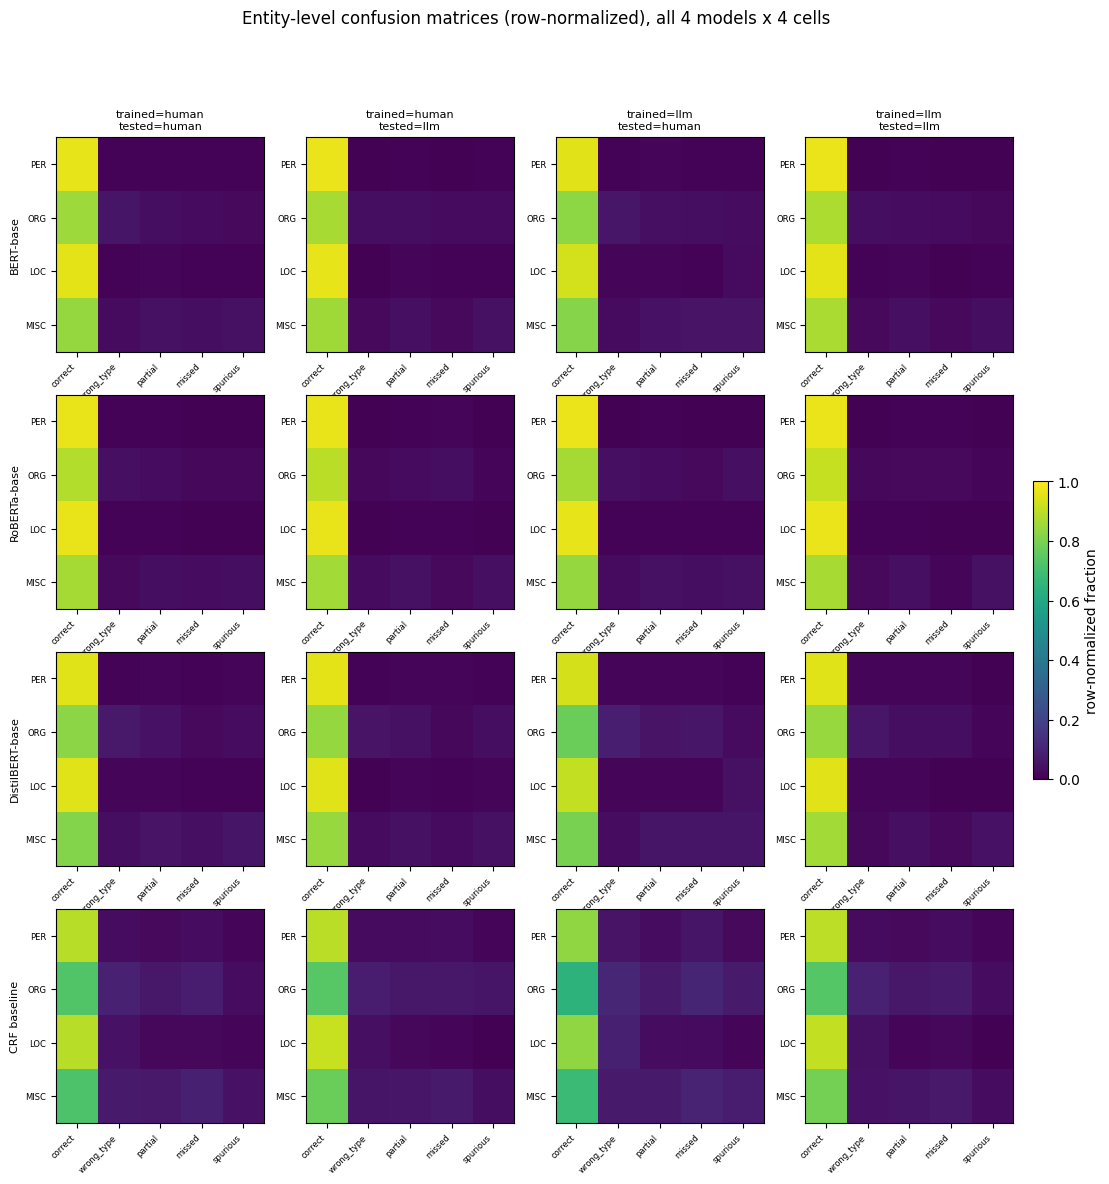

Saved /content/drive/MyDrive/IT469-NER-Project/results/analysis/figures/confusion_entity_norm_grid.png


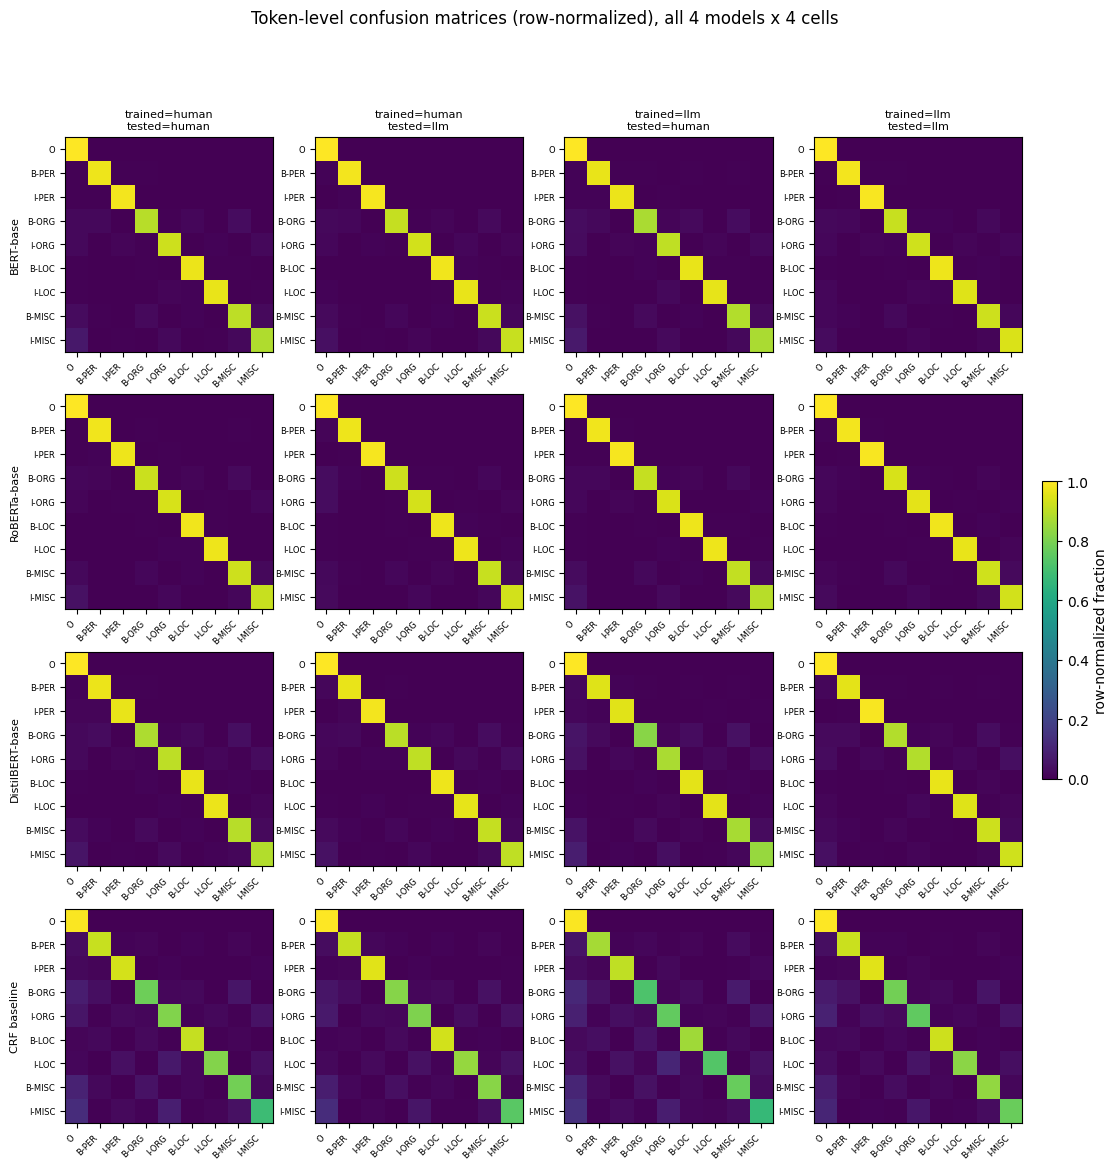

Saved /content/drive/MyDrive/IT469-NER-Project/results/analysis/figures/confusion_token_norm_grid.png


In [22]:
# Combined comparison figure: entity-level normalized confusion, rows=model, cols=(trained,tested) cell.
def plot_cross_model_confusion_grid(cms_dict, labels, title, out_path):
    fig, axes = plt.subplots(len(MODEL_TAGS), len(CELLS), figsize=(3.2 * len(CELLS), 3.2 * len(MODEL_TAGS)))
    for row, tag in enumerate(MODEL_TAGS):
        for col, (trained, tested) in enumerate(CELLS):
            ax = axes[row][col]
            df = cms_dict[(tag, trained, tested)]
            im = ax.imshow(df.values, cmap=CMAP_SEQUENTIAL, vmin=0, vmax=1, aspect="auto")
            ax.set_xticks(range(len(df.columns)), df.columns, rotation=45, ha="right", fontsize=6)
            ax.set_yticks(range(len(df.index)), df.index, fontsize=6)
            if row == 0:
                ax.set_title(f"trained={trained}\ntested={tested}", fontsize=8)
            if col == 0:
                ax.set_ylabel(MODEL_DISPLAY_NAMES[tag], fontsize=8)
    fig.colorbar(im, ax=axes, fraction=0.015, pad=0.02, label="row-normalized fraction")
    fig.suptitle(title)
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved {out_path}")


plot_cross_model_confusion_grid(
    all_entity_cms_norm, ENTITY_CM_CATEGORIES,
    "Entity-level confusion matrices (row-normalized), all 4 models x 4 cells",
    FIGURES_DIR / "confusion_entity_norm_grid.png",
)
plot_cross_model_confusion_grid(
    all_token_cms_norm, LABEL_NAMES,
    "Token-level confusion matrices (row-normalized), all 4 models x 4 cells",
    FIGURES_DIR / "confusion_token_norm_grid.png",
)


## 9. Joint paired bootstrap over all 16 combinations

Every individual notebook (04, and each of the three `05_main_models-*`) already ran its OWN 4-comparison
bootstrap in isolation. This section instead builds per-article (tp, fp, fn) counts for **all 16**
(model, trained, tested) combinations at once and draws **one shared article resample per iteration**
across all of them -- which is what makes it valid to compare, say, BERT-base's human-trained-on-human-test
cell against the CRF's human-trained-on-human-test cell with a proper paired CI (both numbers come from
literally the same resampled articles each iteration), something none of the individual notebooks could do
on their own since they never had every model's predictions in memory together.


In [23]:
# Precompute per-article (tp, fp, fn) for all 16 combinations, then verify the summed counts reproduce
# seqeval's micro F1 exactly for every one of them before trusting the bootstrap -- same two-step pattern
# as notebooks 04/05.
counts_by_combo = {}
for tag in MODEL_TAGS:
    for trained in ["human", "llm"]:
        for tested in ["human", "llm"]:
            gold_records, pred_tag_lists = aligned_predictions(tag, trained, tested)
            counts_by_combo[(tag, trained, tested)] = article_counts(gold_records, pred_tag_lists)

for combo, by_article in counts_by_combo.items():
    tag, trained, tested = combo
    tp = sum(c[0] for c in by_article.values())
    fp = sum(c[1] for c in by_article.values())
    fn = sum(c[2] for c in by_article.values())
    our_f1 = _micro_f1_from_counts(tp, fp, fn)
    gold_records, pred_tag_lists = aligned_predictions(tag, trained, tested)
    seqeval_f1 = f1_score([r["ner_tags"] for r in gold_records], pred_tag_lists)
    assert abs(our_f1 - seqeval_f1) < 1e-6, f"{combo}: article_counts F1 {our_f1:.6f} != seqeval F1 {seqeval_f1:.6f}"
logger.info("Verified: summed per-article counts reproduce seqeval's micro F1 exactly for all 16 combinations")
print("Verified: article_counts-derived F1 matches seqeval's F1 exactly (diff < 1e-6) for all 16 combinations.")


2026-11-09 07:25:14,569 [INFO] Verified: summed per-article counts reproduce seqeval's micro F1 exactly for all 16 combinations
INFO:analysis:Verified: summed per-article counts reproduce seqeval's micro F1 exactly for all 16 combinations


Verified: article_counts-derived F1 matches seqeval's F1 exactly (diff < 1e-6) for all 16 combinations.


In [24]:
# The 40 comparisons: (a) the 4 notebook-04-style comparisons, per model (4 models x 4 = 16); (b) each
# transformer minus the CRF, in each of the 4 cells (3 x 4 = 12); (c) each pairwise transformer-vs
# -transformer difference, in each of the 4 cells (3 pairs x 4 = 12).
joint_comparisons = {}

for tag in MODEL_TAGS:
    joint_comparisons[f"{tag}: human_test, human_trained-llm_trained"] = ((tag, "human", "human"), (tag, "llm", "human"))
    joint_comparisons[f"{tag}: llm_test, human_trained-llm_trained"] = ((tag, "human", "llm"), (tag, "llm", "llm"))
    joint_comparisons[f"{tag}: human_trained, human_test-llm_test"] = ((tag, "human", "human"), (tag, "human", "llm"))
    joint_comparisons[f"{tag}: llm_trained, human_test-llm_test"] = ((tag, "llm", "human"), (tag, "llm", "llm"))

for tag in TRANSFORMER_TAGS:
    for trained, tested in CELLS:
        joint_comparisons[f"{tag}-crf: trained={trained},tested={tested}"] = ((tag, trained, tested), ("crf", trained, tested))

for tag_a, tag_b in itertools.combinations(TRANSFORMER_TAGS, 2):
    for trained, tested in CELLS:
        joint_comparisons[f"{tag_a}-{tag_b}: trained={trained},tested={tested}"] = ((tag_a, trained, tested), (tag_b, trained, tested))

print(f"Built {len(joint_comparisons)} comparisons (expected 40).")
assert len(joint_comparisons) == 40, f"expected 40 comparisons, got {len(joint_comparisons)}"

joint_bootstrap_df = paired_bootstrap(counts_by_combo, joint_comparisons, N_BOOTSTRAP, SEED)
joint_bootstrap_df.to_csv(TABLES_DIR / "joint_bootstrap.csv", index=False)
display(joint_bootstrap_df)


Built 40 comparisons (expected 40).


,comparison,observed_difference,ci_low,ci_high,reliable
0,"bert-base-cased: human_test, human_trained-llm...",0.012983,0.009253,0.016864,True
1,"bert-base-cased: llm_test, human_trained-llm_t...",-0.002525,-0.006836,0.002198,False
2,"bert-base-cased: human_trained, human_test-llm...",-0.007259,-0.015990,0.001731,False
3,"bert-base-cased: llm_trained, human_test-llm_test",-0.022766,-0.032882,-0.012054,True
4,"roberta-base: human_test, human_trained-llm_tr...",0.005387,0.001900,0.008777,True
5,"roberta-base: llm_test, human_trained-llm_trained",-0.004724,-0.008864,-0.000645,True
6,"roberta-base: human_trained, human_test-llm_test",-0.001374,-0.008999,0.006070,False
7,"roberta-base: llm_trained, human_test-llm_test",-0.011485,-0.019969,-0.002641,True
8,"distilbert-base-cased: human_test, human_train...",0.020152,0.015365,0.024623,True
9,"distilbert-base-cased: llm_test, human_trained...",-0.001688,-0.007591,0.004553,False


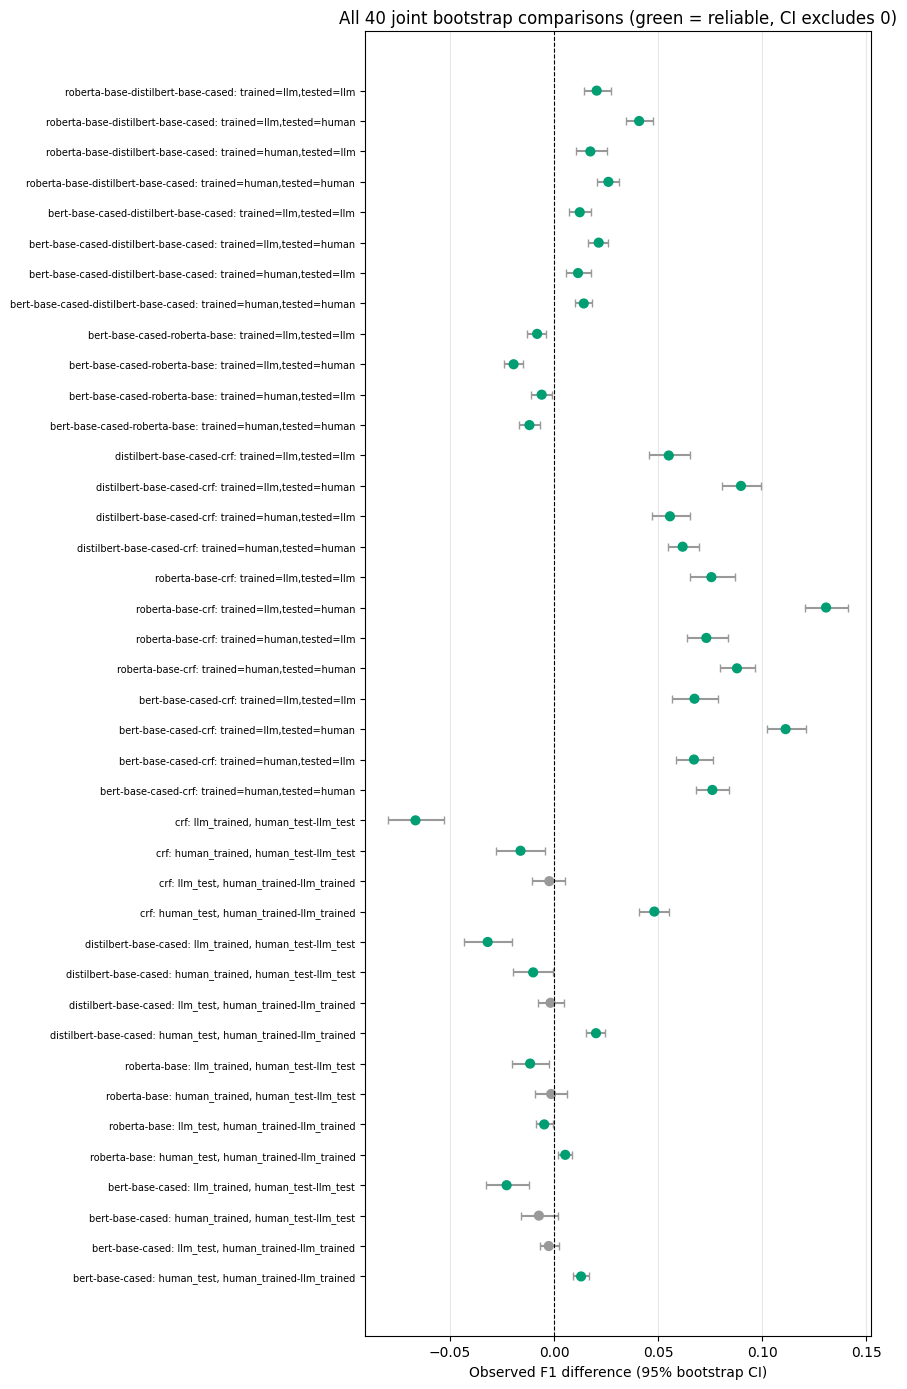

Saved /content/drive/MyDrive/IT469-NER-Project/results/analysis/figures/joint_bootstrap.png


In [25]:
# Figure: all 40 bootstrap differences with their 95% CI, grouped by comparison family, colored by
# whether the interval excludes zero.
fig, ax = plt.subplots(figsize=(9, 14))
y_pos = np.arange(len(joint_bootstrap_df))
colors = [PALETTE["green"] if r else PALETTE["grey"] for r in joint_bootstrap_df["reliable"]]
lower_err = joint_bootstrap_df["observed_difference"] - joint_bootstrap_df["ci_low"]
upper_err = joint_bootstrap_df["ci_high"] - joint_bootstrap_df["observed_difference"]
ax.errorbar(joint_bootstrap_df["observed_difference"], y_pos, xerr=[lower_err, upper_err],
            fmt="o", capsize=3, color=PALETTE["grey"], ecolor=PALETTE["grey"], zorder=1, markersize=4)
ax.scatter(joint_bootstrap_df["observed_difference"], y_pos, c=colors, s=40, zorder=2)
ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_yticks(y_pos, joint_bootstrap_df["comparison"], fontsize=7)
ax.set_xlabel("Observed F1 difference (95% bootstrap CI)")
ax.set_title("All 40 joint bootstrap comparisons (green = reliable, CI excludes 0)")
ax.grid(alpha=0.3, axis="x")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "joint_bootstrap.png", dpi=300)
plt.show()
print(f"Saved {FIGURES_DIR / 'joint_bootstrap.png'}")


## 10. RQ1 -- does NER work as well on LLM-generated text as on human-written text?

Held fixed: the training side. Compared: F1 on human test vs. F1 on LLM test. This is exactly the
"X_trained, human_test-llm_test" rows of the joint bootstrap (Section 9), for all 4 models and both
training sides (8 rows total).


In [26]:
# Pull RQ1's 8 rows (both training sides, all 4 models) out of the joint bootstrap table built above.
rq1_df = joint_bootstrap_df[joint_bootstrap_df["comparison"].str.contains("human_test-llm_test")].copy()
rq1_df.to_csv(TABLES_DIR / "rq1_test_domain.csv", index=False)
display(rq1_df)


,comparison,observed_difference,ci_low,ci_high,reliable
2,"bert-base-cased: human_trained, human_test-llm...",-0.007259,-0.015990,0.001731,False
3,"bert-base-cased: llm_trained, human_test-llm_test",-0.022766,-0.032882,-0.012054,True
6,"roberta-base: human_trained, human_test-llm_test",-0.001374,-0.008999,0.006070,False
7,"roberta-base: llm_trained, human_test-llm_test",-0.011485,-0.019969,-0.002641,True
10,"distilbert-base-cased: human_trained, human_te...",-0.010020,-0.019620,-0.000306,True
11,"distilbert-base-cased: llm_trained, human_test...",-0.031860,-0.043435,-0.020100,True
14,"crf: human_trained, human_test-llm_test",-0.016095,-0.027899,-0.004247,True
15,"crf: llm_trained, human_test-llm_test",-0.066518,-0.079658,-0.053039,True


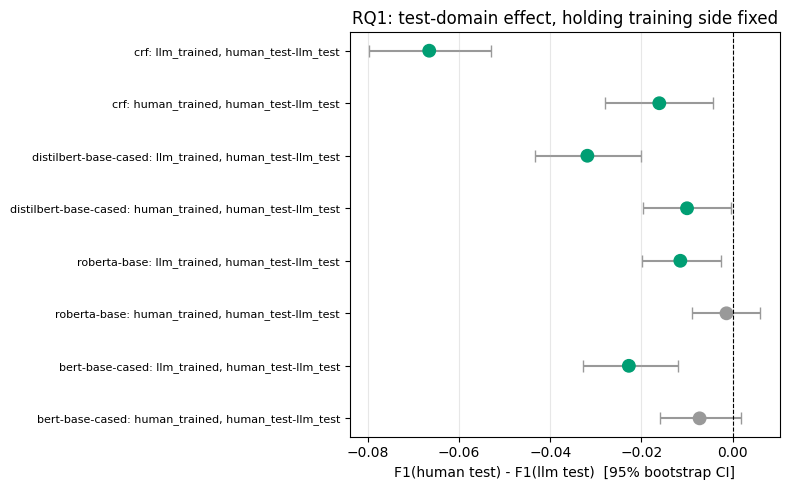

RQ1 interpretation (from computed values only): 6/8 rows show a RELIABLY negative difference, i.e. F1 is higher on LLM-generated test text than on human-written test text, for that (model, training side) pair. Every reliable row points the same direction -- NER does not perform as well on human-written text as on LLM-generated text, consistent with notebook 03's finding that LLM text has lower entity density.


In [27]:
# Plot RQ1's 8 comparisons as a forest plot (observed difference + 95% CI).
fig, ax = plt.subplots(figsize=(8, 5))
y_pos = np.arange(len(rq1_df))
colors = [PALETTE["green"] if r else PALETTE["grey"] for r in rq1_df["reliable"]]
lower_err = rq1_df["observed_difference"] - rq1_df["ci_low"]
upper_err = rq1_df["ci_high"] - rq1_df["observed_difference"]
ax.errorbar(rq1_df["observed_difference"], y_pos, xerr=[lower_err, upper_err],
            fmt="o", capsize=4, color=PALETTE["grey"], ecolor=PALETTE["grey"], zorder=1)
ax.scatter(rq1_df["observed_difference"], y_pos, c=colors, s=80, zorder=2)
ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_yticks(y_pos, rq1_df["comparison"], fontsize=8)
ax.set_xlabel("F1(human test) - F1(llm test)  [95% bootstrap CI]")
ax.set_title("RQ1: test-domain effect, holding training side fixed")
ax.grid(alpha=0.3, axis="x")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "rq1_test_domain.png", dpi=300)
plt.show()

_n_negative_reliable = int(((rq1_df["observed_difference"] < 0) & rq1_df["reliable"]).sum())
print(
    f"RQ1 interpretation (from computed values only): {_n_negative_reliable}/{len(rq1_df)} rows show a "
    "RELIABLY negative difference, i.e. F1 is higher on LLM-generated test text than on human-written "
    "test text, for that (model, training side) pair. "
    + ("Every reliable row points the same direction -- NER does not perform as well on human-written "
       "text as on LLM-generated text, consistent with notebook 03's finding that LLM text has lower "
       "entity density." if _n_negative_reliable == int(rq1_df['reliable'].sum()) and _n_negative_reliable > 0
       else "Rows disagree in direction or reliability -- see the table above before drawing a single conclusion.")
)


## 11. RQ2 -- can LLM-generated articles substitute for human-written ones as training data?

Held fixed: the test side. Compared: F1 when trained on human text vs. F1 when trained on LLM text. This
is exactly the "X_test, human_trained-llm_trained" rows of the joint bootstrap (Section 9), for all 4
models and both test sides (8 rows total).


In [28]:
# Pull RQ2's 8 rows (both test sides, all 4 models) out of the joint bootstrap table built above.
rq2_df = joint_bootstrap_df[joint_bootstrap_df["comparison"].str.contains("human_trained-llm_trained")].copy()
rq2_df.to_csv(TABLES_DIR / "rq2_train_domain.csv", index=False)
display(rq2_df)


,comparison,observed_difference,ci_low,ci_high,reliable
0,"bert-base-cased: human_test, human_trained-llm...",0.012983,0.009253,0.016864,True
1,"bert-base-cased: llm_test, human_trained-llm_t...",-0.002525,-0.006836,0.002198,False
4,"roberta-base: human_test, human_trained-llm_tr...",0.005387,0.001900,0.008777,True
5,"roberta-base: llm_test, human_trained-llm_trained",-0.004724,-0.008864,-0.000645,True
8,"distilbert-base-cased: human_test, human_train...",0.020152,0.015365,0.024623,True
9,"distilbert-base-cased: llm_test, human_trained...",-0.001688,-0.007591,0.004553,False
12,"crf: human_test, human_trained-llm_trained",0.048151,0.040786,0.055326,True
13,"crf: llm_test, human_trained-llm_trained",-0.002272,-0.010376,0.005193,False


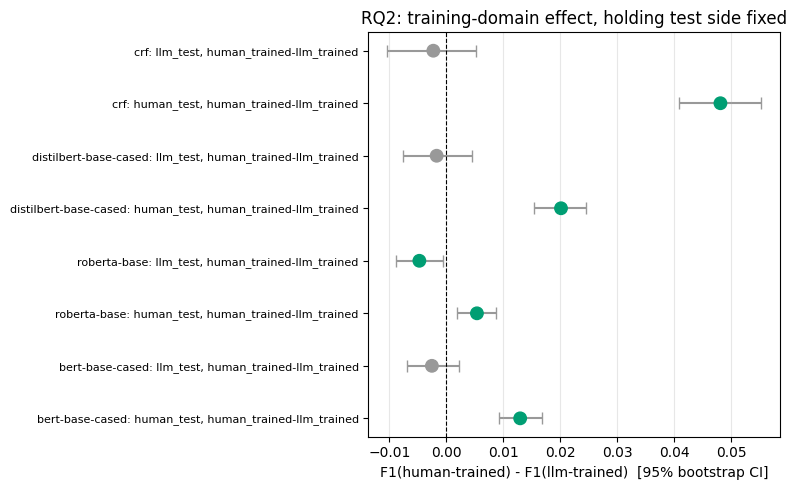

RQ2 interpretation (from computed values only): 4/8 rows show a RELIABLY positive difference, i.e. training on human text beats training on LLM text for that (model, test side) pair; 1/8 reliable row(s) point the other way or are not reliable. Human-written text is therefore NOT safely substitutable by LLM-generated text as NER training data, at least not without a same-test-domain match, consistent with notebook 04's CRF finding.


In [29]:
# Plot RQ2's 8 comparisons as a forest plot (observed difference + 95% CI).
fig, ax = plt.subplots(figsize=(8, 5))
y_pos = np.arange(len(rq2_df))
colors = [PALETTE["green"] if r else PALETTE["grey"] for r in rq2_df["reliable"]]
lower_err = rq2_df["observed_difference"] - rq2_df["ci_low"]
upper_err = rq2_df["ci_high"] - rq2_df["observed_difference"]
ax.errorbar(rq2_df["observed_difference"], y_pos, xerr=[lower_err, upper_err],
            fmt="o", capsize=4, color=PALETTE["grey"], ecolor=PALETTE["grey"], zorder=1)
ax.scatter(rq2_df["observed_difference"], y_pos, c=colors, s=80, zorder=2)
ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_yticks(y_pos, rq2_df["comparison"], fontsize=8)
ax.set_xlabel("F1(human-trained) - F1(llm-trained)  [95% bootstrap CI]")
ax.set_title("RQ2: training-domain effect, holding test side fixed")
ax.grid(alpha=0.3, axis="x")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "rq2_train_domain.png", dpi=300)
plt.show()

_n_positive_reliable = int(((rq2_df["observed_difference"] > 0) & rq2_df["reliable"]).sum())
_n_reliable = int(rq2_df["reliable"].sum())
print(
    f"RQ2 interpretation (from computed values only): {_n_positive_reliable}/{len(rq2_df)} rows show a "
    "RELIABLY positive difference, i.e. training on human text beats training on LLM text for that "
    "(model, test side) pair; "
    f"{_n_reliable - _n_positive_reliable}/{len(rq2_df)} reliable row(s) point the other way or are not reliable. "
    + ("Human-written text is therefore NOT safely substitutable by LLM-generated text as NER training "
       "data, at least not without a same-test-domain match, consistent with notebook 04's CRF finding."
       if _n_positive_reliable > 0 else
       "No row shows a reliable advantage for human-trained models here -- re-check the table above.")
)


## 12. RQ3 -- which entity types and topics are most affected by text origin, across all 4 models?

"Origin" = human test vs. LLM test, holding the trained model fixed -- the same definition notebook 04
Section 14 used for the CRF alone. Here the per-type and per-topic origin gaps from all 4 models'
`per_type_origin_gap.csv` / `per_topic_origin_gap.csv` (already computed by each source notebook) are
combined, ranked, and cross-checked for agreement across models. These remain **descriptive point
estimates** -- per-cell samples are too small for an individual bootstrap CI per type/topic, same caveat
every earlier notebook stated.


In [30]:
# Combine all 4 models' per-type origin gaps (already computed by each source notebook) into one table.
rq3_type_df = per_type_origin_gap_all[["model", "trained_on", "entity_type", "human", "llm", "origin_gap", "abs_gap"]].copy()
rq3_type_df["model_display"] = rq3_type_df["model"].map(MODEL_DISPLAY_NAMES)
rq3_type_df.to_csv(TABLES_DIR / "rq3_type_gap.csv", index=False)
display(rq3_type_df.sort_values(["model", "trained_on", "abs_gap"], ascending=[True, True, False]))


,model,trained_on,entity_type,human,llm,origin_gap,abs_gap,model_display
0,bert-base-cased,human,MISC,0.876464,0.894940,-0.018475,0.018475,BERT-base
1,bert-base-cased,human,ORG,0.890250,0.905294,-0.015044,0.015044,BERT-base
2,bert-base-cased,human,LOC,0.959184,0.962793,-0.003609,0.003609,BERT-base
3,bert-base-cased,human,PER,0.968012,0.970169,-0.002156,0.002156,BERT-base
4,bert-base-cased,llm,MISC,0.862172,0.903586,-0.041414,0.041414,BERT-base
5,bert-base-cased,llm,ORG,0.871516,0.903245,-0.031729,0.031729,BERT-base
6,bert-base-cased,llm,LOC,0.940898,0.966381,-0.025483,0.025483,BERT-base
7,bert-base-cased,llm,PER,0.962652,0.969764,-0.007112,0.007112,BERT-base
24,crf,human,MISC,0.778867,0.830926,-0.052060,0.052060,CRF baseline
25,crf,human,LOC,0.909589,0.924366,-0.014777,0.014777,CRF baseline


In [31]:
# Combine all 4 models' per-topic origin gaps (already computed by each source notebook) into one table.
rq3_topic_df = per_topic_origin_gap_all[["model", "trained_on", "topic", "human", "llm", "origin_gap", "abs_gap"]].copy()
rq3_topic_df["model_display"] = rq3_topic_df["model"].map(MODEL_DISPLAY_NAMES)
rq3_topic_df.to_csv(TABLES_DIR / "rq3_topic_gap.csv", index=False)
display(rq3_topic_df.sort_values(["model", "trained_on", "abs_gap"], ascending=[True, True, False]))


,model,trained_on,topic,human,llm,origin_gap,abs_gap,model_display
0,bert-base-cased,human,Celebrity,0.876993,0.914157,-0.037164,0.037164,BERT-base
1,bert-base-cased,human,History and religion,0.936082,0.922053,0.014029,0.014029,BERT-base
2,bert-base-cased,human,Sports,0.930767,0.942466,-0.011698,0.011698,BERT-base
3,bert-base-cased,human,Social culture and civil rights,0.939059,0.944367,-0.005308,0.005308,BERT-base
4,bert-base-cased,human,Politics and government,0.967419,0.969916,-0.002497,0.002497,BERT-base
5,bert-base-cased,human,Science and technology,0.945055,0.943662,0.001393,0.001393,BERT-base
6,bert-base-cased,llm,Celebrity,0.858677,0.915840,-0.057163,0.057163,BERT-base
7,bert-base-cased,llm,Sports,0.911351,0.944031,-0.032680,0.032680,BERT-base
8,bert-base-cased,llm,Social culture and civil rights,0.922512,0.948905,-0.026393,0.026393,BERT-base
9,bert-base-cased,llm,Science and technology,0.935223,0.951036,-0.015813,0.015813,BERT-base


In [32]:
# Cross-model consistency check: for each entity type (resp. topic), rank it by origin_gap within each
# (model, trained_on) group, then correlate those rankings across models with Spearman rank correlation
# (pandas' own rank-based corr, no scipy dependency) -- if independently-trained models agree on which
# types/topics are most affected, that's evidence the ranking reflects something real about the text, not
# noise in one model's fit.
def cross_model_rank_corr(gap_df, group_col):
    pivot = gap_df.pivot_table(index=group_col, columns=["model", "trained_on"], values="origin_gap")
    return pivot.corr(method="spearman")


type_rank_corr = cross_model_rank_corr(rq3_type_df, "entity_type")
topic_rank_corr = cross_model_rank_corr(rq3_topic_df, "topic")
type_rank_corr.to_csv(TABLES_DIR / "rq3_type_rank_correlation.csv")
topic_rank_corr.to_csv(TABLES_DIR / "rq3_topic_rank_correlation.csv")

print("Entity-type origin-gap rank correlation across (model, trained_on) groups:")
display(type_rank_corr)
print("\nTopic origin-gap rank correlation across (model, trained_on) groups:")
display(topic_rank_corr)

_off_diag_type = type_rank_corr.values[~np.eye(type_rank_corr.shape[0], dtype=bool)]
_off_diag_topic = topic_rank_corr.values[~np.eye(topic_rank_corr.shape[0], dtype=bool)]
print(
    f"\nMean off-diagonal rank correlation: entity type = {np.nanmean(_off_diag_type):.3f}, "
    f"topic = {np.nanmean(_off_diag_topic):.3f}. Values close to 1 mean independently-trained models "
    "agree on which entity types/topics are most affected by text origin; values near 0 mean they don't."
)


Entity-type origin-gap rank correlation across (model, trained_on) groups:


model                            bert-base-cased        crf       \
trained_on                                 human  llm human  llm   
model                 trained_on                                   
bert-base-cased       human                  1.0  1.0   0.8  1.0   
                      llm                    1.0  1.0   0.8  1.0   
crf                   human                  0.8  0.8   1.0  0.8   
                      llm                    1.0  1.0   0.8  1.0   
distilbert-base-cased human                  0.8  0.8   0.4  0.8   
                      llm                    1.0  1.0   0.8  1.0   
roberta-base          human                 -0.2 -0.2  -0.4 -0.2   
                      llm                    0.8  0.8   0.4  0.8   

model                            distilbert-base-cased      roberta-base       
trained_on                                       human  llm        human  llm  
model                 trained_on                                               
bert-base-cased       human                        0.8  1.0         -0.2  0.8  
                      llm                          0.8  1.0         -0.2  0.8  
crf                   human                        0.4  0.8         -0.4  0.4  
                      llm                          0.8  1.0         -0.2  0.8  
distilbert-base-cased human                        1.0  0.8         -0.4  0.6  
                      llm                          0.8  1.0         -0.2  0.8  
roberta-base          human                       -0.4 -0.2          1.0  0.4  
                      llm                          0.6  0.8          0.4  1.0


Topic origin-gap rank correlation across (model, trained_on) groups:


model                            bert-base-cased                 crf  \
trained_on                                 human       llm     human   
model                 trained_on                                       
bert-base-cased       human             1.000000  0.942857  0.942857   
                      llm               0.942857  1.000000  0.828571   
crf                   human             0.942857  0.828571  1.000000   
                      llm               0.885714  0.771429  0.828571   
distilbert-base-cased human             0.942857  0.828571  1.000000   
                      llm               1.000000  0.942857  0.942857   
roberta-base          human             0.600000  0.771429  0.371429   
                      llm               1.000000  0.942857  0.942857   

model                                      distilbert-base-cased            \
trained_on                             llm                 human       llm   
model                 trained_on                                             
bert-base-cased       human       0.885714              0.942857  1.000000   
                      llm         0.771429              0.828571  0.942857   
crf                   human       0.828571              1.000000  0.942857   
                      llm         1.000000              0.828571  0.885714   
distilbert-base-cased human       0.828571              1.000000  0.942857   
                      llm         0.885714              0.942857  1.000000   
roberta-base          human       0.314286              0.371429  0.600000   
                      llm         0.885714              0.942857  1.000000   

model                            roberta-base            
trained_on                              human       llm  
model                 trained_on                         
bert-base-cased       human          0.600000  1.000000  
                      llm            0.771429  0.942857  
crf                   human          0.371429  0.942857  
                      llm            0.314286  0.885714  
distilbert-base-cased human          0.371429  0.942857  
                      llm            0.600000  1.000000  
roberta-base          human          1.000000  0.600000  
                      llm            0.600000  1.000000


Mean off-diagonal rank correlation: entity type = 0.564, topic = 0.816. Values close to 1 mean independently-trained models agree on which entity types/topics are most affected by text origin; values near 0 mean they don't.


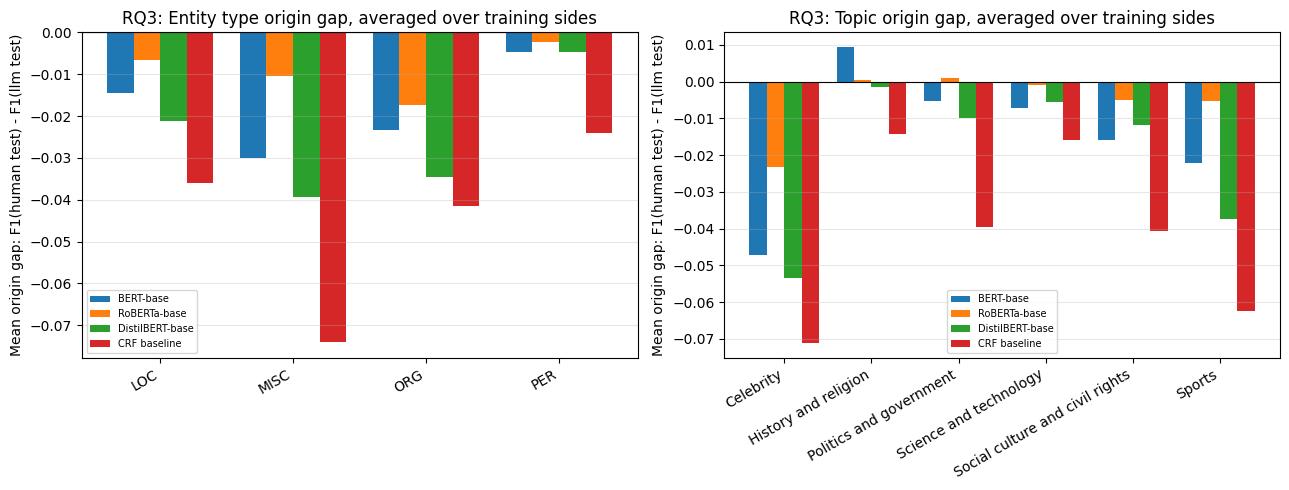

Saved /content/drive/MyDrive/IT469-NER-Project/results/analysis/figures/rq3_origin_gap.png


In [33]:
# RQ3 figure: mean origin gap per entity type and per topic, one bar group per model.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (df, group_col, label) in zip(
    axes, [(rq3_type_df, "entity_type", "Entity type"), (rq3_topic_df, "topic", "Topic")]
):
    pivot = df.pivot_table(index=group_col, columns="model", values="origin_gap", aggfunc="mean")
    pivot = pivot.reindex(columns=MODEL_TAGS)
    x = np.arange(len(pivot.index))
    width = 0.8 / len(MODEL_TAGS)
    for i, tag in enumerate(MODEL_TAGS):
        ax.bar(x + (i - (len(MODEL_TAGS) - 1) / 2) * width, pivot[tag].values, width, label=MODEL_DISPLAY_NAMES[tag])
    ax.set_xticks(x, pivot.index, rotation=30, ha="right")
    ax.set_ylabel("Mean origin gap: F1(human test) - F1(llm test)")
    ax.set_title(f"RQ3: {label} origin gap, averaged over training sides")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "rq3_origin_gap.png", dpi=300)
plt.show()
print(f"Saved {FIGURES_DIR / 'rq3_origin_gap.png'}")


## 13. Entity distribution per text source and split

This reuses notebook 03's `entity_counts.csv` / `entity_stats.csv` (promised in the project proposal, and
already the right computation -- no need to redo it here) rather than recomputing from raw silver data, and
adds one comparison figure spanning all splits at once.


In [34]:
# Display notebook 03's entity counts and stats tables as-is (already the right computation).
display(entity_counts_df.pivot_table(index=["side", "split"], columns="entity_type", values="n_mentions"))
display(entity_stats_df)


entity_type              LOC     MISC      ORG      PER
side  split                                            
human test            3307.0   3352.0   2989.0   4878.0
      train          26072.0  25648.0  28174.0  38833.0
      train_matched  20069.0  19650.0  21636.0  29825.0
      validation      3275.0   3116.0   3332.0   4807.0
llm   test            2156.0   2321.0   1724.0   2677.0
      train          16639.0  18692.0  15977.0  20639.0
      validation      2082.0   2396.0   1835.0   2368.0

,side,split,n_sentences,n_tokens,n_entities,entities_per_100_tokens,pct_sentences_no_entity,n_distinct_entity_strings
0,human,train,72307,1751319,118727,6.779,31.17,28937
1,human,validation,9060,219427,14530,6.622,30.86,5584
2,human,test,9132,217464,14526,6.680,32.30,5828
3,llm,train,50521,1342562,71947,5.359,30.80,13807
4,llm,validation,6221,168119,8681,5.164,30.99,2749
5,llm,test,6265,167623,8878,5.296,31.62,2942
6,human,train_matched,55394,1342507,91180,6.792,31.16,24429


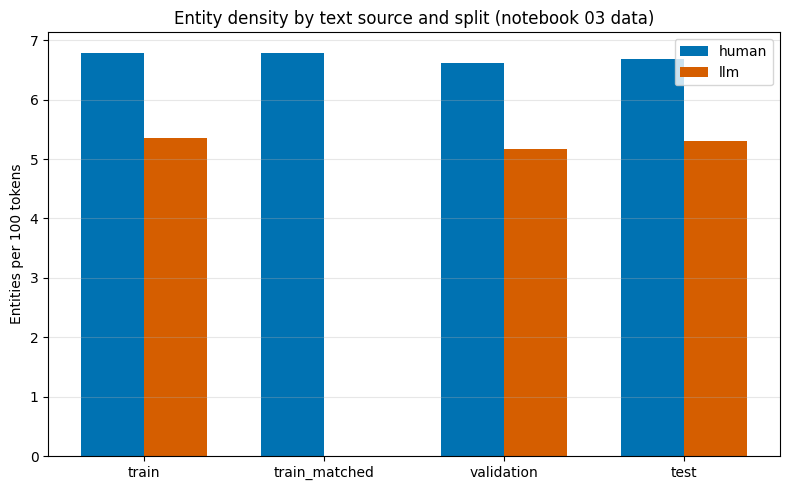

Saved /content/drive/MyDrive/IT469-NER-Project/results/analysis/figures/entity_distribution.png


In [35]:
# Entities per 100 tokens, human vs. LLM, across all splits (train/validation/test, plus the matched
# training subset) -- extends notebook 03's own entity_density.png (which only covered train/val/test) by
# also showing train_matched next to llm/train for a direct apples-to-apples comparison.
_splits_order = ["train", "train_matched", "validation", "test"]
_plot_df = entity_stats_df[entity_stats_df["split"].isin(_splits_order)].copy()
_plot_df["split"] = pd.Categorical(_plot_df["split"], categories=_splits_order, ordered=True)
_plot_df = _plot_df.sort_values("split")

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(_splits_order))
width = 0.35
for i, side in enumerate(["human", "llm"]):
    sub = _plot_df[_plot_df["side"] == side].set_index("split").reindex(_splits_order)
    ax.bar(x + (i - 0.5) * width, sub["entities_per_100_tokens"].values, width, label=side, color=PALETTE[side])
ax.set_xticks(x, _splits_order)
ax.set_ylabel("Entities per 100 tokens")
ax.set_title("Entity density by text source and split (notebook 03 data)")
ax.legend()
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "entity_distribution.png", dpi=300)
plt.show()
print(f"Saved {FIGURES_DIR / 'entity_distribution.png'}")


## 14. Vocabulary mechanism test

For each model and each of its 4 (trained, tested) cells: recall on gold entity mentions that were SEEN
vs. UNSEEN in that cell's training side's entity vocabulary (lowercased exact string match). This extends
notebook 04 Section 13's leakage check (which only measured raw vocabulary *coverage*, not recall
*conditioned* on seen/unseen) across all 4 models. **Interpret cautiously**: a lower recall on unseen
mentions is consistent with -- but does not prove -- that lexical memorization explains part of each
model's performance; these models use learned embeddings, not just lexical features like the CRF, so the
effect is expected to be weaker for them than for the CRF.


In [36]:
# Training-side entity vocabulary depends only on the silver training data, not on which model trained on
# it -- so it's built once per side and shared across all 4 models' cells.
def entity_vocab(records):
    vocab = set()
    for r in records:
        for (etype, s, e) in extract_spans(r["ner_tags"]):
            vocab.add(" ".join(r["tokens"][s:e]).lower())
    return vocab


train_vocab = {side: entity_vocab(silver[(side, "train")]) for side in ["human", "llm"]}
print(f"Train vocabulary sizes: human={len(train_vocab['human'])}, llm={len(train_vocab['llm'])} distinct entity strings")


Train vocabulary sizes: human=24429, llm=13807 distinct entity strings


In [37]:
# The CRF's entity_vocab_coverage.csv (notebook 04 Section 13.2) is model-independent -- it depends only on
# train/test text, not on which model predicted -- so it's reused as-is rather than recomputed.
entity_vocab_coverage_df = pd.read_csv(results_dir_for("crf") / "entity_vocab_coverage.csv")
entity_vocab_coverage_df.to_csv(TABLES_DIR / "entity_vocab_coverage.csv", index=False)
display(entity_vocab_coverage_df.pivot(index="train_side", columns="test_side", values="pct_covered_by_train_vocab"))


test_side,human,llm
train_side,,
human,71.99,77.63
llm,65.76,74.56


In [38]:
# Recall on gold mentions seen vs. unseen in the training vocabulary, for all 16 (model, trained, tested)
# combinations.
def recall_by_vocab_membership(gold_records, pred_tag_lists, vocab):
    seen_tp, seen_total, unseen_tp, unseen_total = 0, 0, 0, 0
    for rec, pred_tags in zip(gold_records, pred_tag_lists):
        gold_spans = extract_spans(rec["ner_tags"])
        pred_spans = set(extract_spans(pred_tags))
        for (etype, s, e) in gold_spans:
            mention = " ".join(rec["tokens"][s:e]).lower()
            matched = (etype, s, e) in pred_spans
            if mention in vocab:
                seen_total += 1
                seen_tp += int(matched)
            else:
                unseen_total += 1
                unseen_tp += int(matched)
    recall_seen = seen_tp / seen_total if seen_total else float("nan")
    recall_unseen = unseen_tp / unseen_total if unseen_total else float("nan")
    return recall_seen, recall_unseen, seen_total, unseen_total


vocab_recall_rows = []
for tag in MODEL_TAGS:
    for trained in ["human", "llm"]:
        for tested in ["human", "llm"]:
            gold_records, pred_tag_lists = aligned_predictions(tag, trained, tested)
            recall_seen, recall_unseen, n_seen, n_unseen = recall_by_vocab_membership(gold_records, pred_tag_lists, train_vocab[trained])
            vocab_recall_rows.append({
                "model": tag, "trained_on": trained, "tested_on": tested,
                "recall_seen": recall_seen, "recall_unseen": recall_unseen,
                "n_seen_mentions": n_seen, "n_unseen_mentions": n_unseen,
                "recall_gap": recall_seen - recall_unseen,
            })

vocab_recall_df = pd.DataFrame(vocab_recall_rows)
vocab_recall_df.to_csv(TABLES_DIR / "vocab_recall.csv", index=False)
display(vocab_recall_df)


,model,trained_on,tested_on,recall_seen,recall_unseen,n_seen_mentions,n_unseen_mentions,recall_gap
0,bert-base-cased,human,human,0.949603,0.878103,10457,4069,0.071500
1,bert-base-cased,human,llm,0.955891,0.882175,6892,1986,0.073716
2,bert-base-cased,llm,human,0.943159,0.869495,9553,4973,0.073664
3,bert-base-cased,llm,llm,0.957244,0.890217,6619,2259,0.067027
4,roberta-base,human,human,0.956202,0.904153,10457,4069,0.052048
5,roberta-base,human,llm,0.956761,0.883686,6892,1986,0.073076
6,roberta-base,llm,human,0.956453,0.902272,9553,4973,0.054181
7,roberta-base,llm,llm,0.962381,0.909252,6619,2259,0.053129
8,distilbert-base-cased,human,human,0.941953,0.857459,10457,4069,0.084494
9,distilbert-base-cased,human,llm,0.947475,0.859517,6892,1986,0.087959


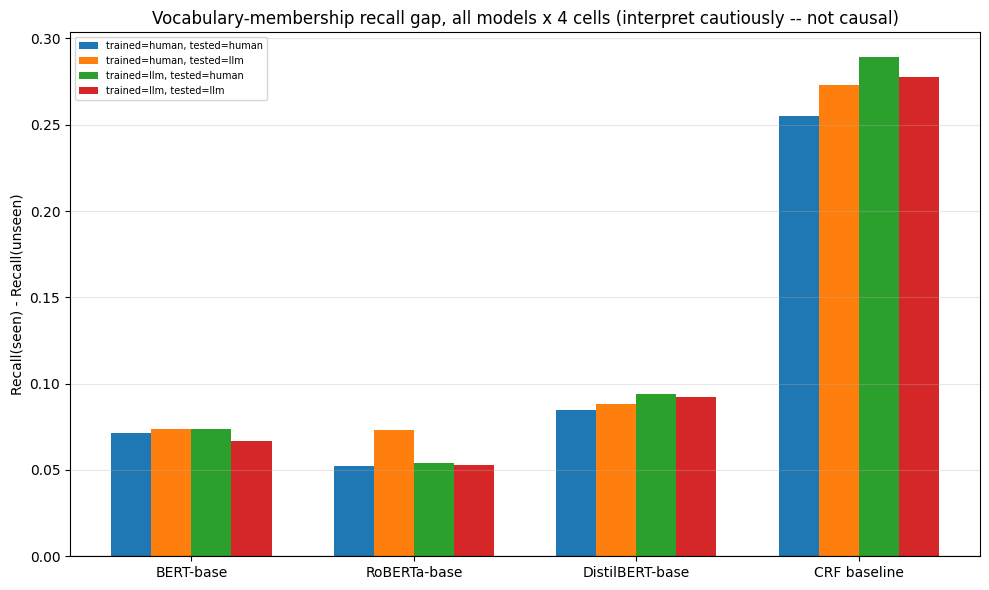

Saved /content/drive/MyDrive/IT469-NER-Project/results/analysis/figures/vocab_recall.png
Interpretation (descriptive only): a positive gap means the model recalls previously-seen entity strings better than novel ones. This is CONSISTENT WITH partial lexical memorization but does not prove it causes any specific F1 difference seen elsewhere in this notebook -- named entities are open-vocabulary, and even the best 2x2 cell in notebook 04 only had ~72% train-vocabulary coverage.


In [39]:
# Figure: the seen-vs-unseen recall gap, grouped by cell, one bar group per model.
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(MODEL_TAGS))
width = 0.18
for i, (trained, tested) in enumerate(CELLS):
    sub = vocab_recall_df[(vocab_recall_df["trained_on"] == trained) & (vocab_recall_df["tested_on"] == tested)].set_index("model").reindex(MODEL_TAGS)
    ax.bar(x + (i - 1.5) * width, sub["recall_gap"].values, width, label=f"trained={trained}, tested={tested}")
ax.set_xticks(x, [MODEL_DISPLAY_NAMES[t] for t in MODEL_TAGS])
ax.set_ylabel("Recall(seen) - Recall(unseen)")
ax.set_title("Vocabulary-membership recall gap, all models x 4 cells (interpret cautiously -- not causal)")
ax.axhline(0, color="black", linewidth=0.8)
ax.legend(fontsize=7)
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "vocab_recall.png", dpi=300)
plt.show()
print(f"Saved {FIGURES_DIR / 'vocab_recall.png'}")
print(
    "Interpretation (descriptive only): a positive gap means the model recalls previously-seen entity "
    "strings better than novel ones. This is CONSISTENT WITH partial lexical memorization but does not "
    "prove it causes any specific F1 difference seen elsewhere in this notebook -- named entities are "
    "open-vocabulary, and even the best 2x2 cell in notebook 04 only had ~72% train-vocabulary coverage."
)


## 15. Error analysis

For every one of the 16 (model, trained, tested) combinations, up to `N_ERROR_EXAMPLES_PER_CATEGORY`
example sentences per error category (`wrong_type`, `partial`, `missed`, `spurious`) are saved to
`error_examples/{model}_{trained}_on_{tested}.csv` with sentence context (the gold/predicted entity text
and the surrounding sentence, tokens rejoined with spaces). A few are shown inline here; the rest are only
in the saved CSVs.


In [40]:
# Sample a few concrete error examples per category, with sentence context, for one (model, trained,
# tested) combination.
def sample_error_examples(gold_records, pred_tag_lists, n_per_category=N_ERROR_EXAMPLES_PER_CATEGORY):
    examples_by_category = defaultdict(list)
    for rec, pred_tags in zip(gold_records, pred_tag_lists):
        gold_spans = extract_spans(rec["ner_tags"])
        pred_spans = extract_spans(pred_tags)
        pred_used = [False] * len(pred_spans)
        sentence_text = " ".join(rec["tokens"])
        for g_type, g_s, g_e in gold_spans:
            exact_idx = next((i for i, (p_t, p_s, p_e) in enumerate(pred_spans) if p_s == g_s and p_e == g_e and not pred_used[i]), None)
            p_type, p_text = None, None
            if exact_idx is not None:
                pred_used[exact_idx] = True
                p_type = pred_spans[exact_idx][0]
                p_s2, p_e2 = pred_spans[exact_idx][1], pred_spans[exact_idx][2]
                p_text = " ".join(rec["tokens"][p_s2:p_e2])
                category = "correct" if p_type == g_type else "wrong_type"
            else:
                overlap_idx = next((i for i, (p_t, p_s, p_e) in enumerate(pred_spans) if not pred_used[i] and p_s < g_e and p_e > g_s), None)
                if overlap_idx is not None:
                    pred_used[overlap_idx] = True
                    p_type = pred_spans[overlap_idx][0]
                    p_s2, p_e2 = pred_spans[overlap_idx][1], pred_spans[overlap_idx][2]
                    p_text = " ".join(rec["tokens"][p_s2:p_e2])
                    category = "partial"
                else:
                    category = "missed"
            if category != "correct" and len(examples_by_category[category]) < n_per_category:
                examples_by_category[category].append({
                    "category": category, "sent_id": rec["sent_id"], "article_id": rec["article_id"],
                    "gold_type": g_type, "gold_text": " ".join(rec["tokens"][g_s:g_e]),
                    "predicted_type": p_type, "predicted_text": p_text, "sentence": sentence_text,
                })
        for i, (p_type, p_s, p_e) in enumerate(pred_spans):
            if not pred_used[i] and len(examples_by_category["spurious"]) < n_per_category:
                examples_by_category["spurious"].append({
                    "category": "spurious", "sent_id": rec["sent_id"], "article_id": rec["article_id"],
                    "gold_type": None, "gold_text": None,
                    "predicted_type": p_type, "predicted_text": " ".join(rec["tokens"][p_s:p_e]),
                    "sentence": sentence_text,
                })
    rows = [row for rows in examples_by_category.values() for row in rows]
    return pd.DataFrame(rows)


for tag in MODEL_TAGS:
    for trained in ["human", "llm"]:
        for tested in ["human", "llm"]:
            gold_records, pred_tag_lists = aligned_predictions(tag, trained, tested)
            examples_df = sample_error_examples(gold_records, pred_tag_lists)
            examples_df.to_csv(ERROR_EXAMPLES_DIR / f"{tag}_{trained}_on_{tested}.csv", index=False)

print(f"Saved error-example CSVs for all 16 combinations to {ERROR_EXAMPLES_DIR}")


Saved error-example CSVs for all 16 combinations to /content/drive/MyDrive/IT469-NER-Project/results/analysis/error_examples


In [41]:
# Show a few examples inline for two illustrative combinations: the llm-trained model tested on human
# text (the largest cross-domain effect in notebook 04), for both the CRF and the strongest transformer.
for tag in ["crf", "roberta-base"]:
    print(f"\n=== {MODEL_DISPLAY_NAMES[tag]}, trained=llm, tested=human ===")
    examples_df = pd.read_csv(ERROR_EXAMPLES_DIR / f"{tag}_llm_on_human.csv")
    display(examples_df.head(8))



=== CRF baseline, trained=llm, tested=human ===


,category,sent_id,article_id,gold_type,gold_text,predicted_type,predicted_text,sentence
0,spurious,h_000004_0000,4,NaN,NaN,ORG,Summary Investigation,"Summary Investigation finds estimated 216,000 ..."
1,spurious,h_000004_0007,4,NaN,NaN,MISC,Faced,""" Faced with this scourge , for a very long ti..."
2,spurious,h_000004_0019,4,NaN,NaN,ORG,CHURCH URGED TO,CHURCH URGED TO REFORM
3,spurious,h_000004_0030,4,NaN,NaN,ORG,'DISGRACE,'DISGRACE '
4,spurious,h_000004_0031,4,NaN,NaN,MISC,You,"Francois Devaux , a victim of church abuse and..."
5,wrong_type,h_000004_0001,4,ORG,Catholic,MISC,Catholic,French Catholic Church showed 'cruel indiffere...
6,wrong_type,h_000004_0039,4,PER,Ingrid Melander,MISC,Ingrid Melander,"Additional reporting by Sudip Kar-Gupta , Chri..."
7,wrong_type,h_000011_0000,11,MISC,TikTok,ORG,TikTok,A new poll studying the attitudes of younger A...



=== RoBERTa-base, trained=llm, tested=human ===


,category,sent_id,article_id,gold_type,gold_text,predicted_type,predicted_text,sentence
0,partial,h_000004_0001,4,MISC,French,MISC,French Catholic,French Catholic Church showed 'cruel indiffere...
1,partial,h_000004_0002,4,ORG,Roman,MISC,Roman Catholic,Latest sex abuse scandal to rock the Roman Cat...
2,partial,h_000004_0004,4,ORG,Catholic Church,MISC,Catholic,"PARIS , Oct 5 ( Reuters ) - French clergy sexu..."
3,partial,h_000004_0008,4,ORG,Roman Catholic Church,ORG,Roman,"The revelations , which showed the problem in ..."
4,partial,h_000004_0009,4,PER,Pope,PER,Pope Francis,Pope Francis expressed gratitude towards victi...
5,missed,h_000004_0001,4,ORG,Catholic,NaN,NaN,French Catholic Church showed 'cruel indiffere...
6,missed,h_000004_0002,4,MISC,Catholic,NaN,NaN,Latest sex abuse scandal to rock the Roman Cat...
7,missed,h_000004_0009,4,PER,Francis,NaN,NaN,Pope Francis expressed gratitude towards victi...


## 16. Report assets

LaTeX-ready table files (using the display names from Section 1, not raw tags) and the figures selected
as "final" for the report's Results section, collected under `report_assets/`.


In [42]:
# LaTeX tables, using display names instead of raw model tags.
_master_2x2_latex = master_2x2_df.drop(columns=["model"]).rename(columns={"model_display": "Model"}).pivot_table(
    index="Model", columns=["trained_on", "tested_on"], values="micro_f1"
)
(REPORT_ASSETS_DIR / "master_2x2.tex").write_text(_master_2x2_latex.to_latex(float_format="%.4f"), encoding="utf-8")

_rq1_latex = rq1_df.copy()
(REPORT_ASSETS_DIR / "rq1_test_domain.tex").write_text(
    _rq1_latex.to_latex(index=False, float_format="%.4f"), encoding="utf-8"
)
_rq2_latex = rq2_df.copy()
(REPORT_ASSETS_DIR / "rq2_train_domain.tex").write_text(
    _rq2_latex.to_latex(index=False, float_format="%.4f"), encoding="utf-8"
)
_joint_bootstrap_latex = joint_bootstrap_df.copy()
(REPORT_ASSETS_DIR / "joint_bootstrap.tex").write_text(
    _joint_bootstrap_latex.to_latex(index=False, float_format="%.4f"), encoding="utf-8"
)

print(f"Wrote 4 LaTeX table files to {REPORT_ASSETS_DIR}")


Wrote 4 LaTeX table files to /content/drive/MyDrive/IT469-NER-Project/results/analysis/report_assets


In [43]:
# Copy the figures selected as "final" for the report's Results section.
_final_figures = [
    "confusion_entity_norm_grid.png", "rq1_test_domain.png", "rq2_train_domain.png",
    "rq3_origin_gap.png", "joint_bootstrap.png", "entity_distribution.png",
]
for fname in _final_figures:
    src = FIGURES_DIR / fname
    if src.exists():
        shutil.copy(src, REPORT_ASSETS_DIR / fname)
print(f"Copied {len(_final_figures)} figures to {REPORT_ASSETS_DIR}")


Copied 6 figures to /content/drive/MyDrive/IT469-NER-Project/results/analysis/report_assets


## 17. Summary


In [44]:
# Headline numbers, the 2x2 micro F1 table, RQ1-3 reliability counts, and a present/missing output checklist.
print(f"Annotator (notebook 02): {ANNOTATOR_TAG}, CoNLL-2003 test F1 = {ANNOTATOR_TEST_F1}")
print("Every F1 in this notebook measures agreement with SILVER labels, not gold human annotation.")
print("Each transformer was trained with a single fixed seed (42); the CRF is deterministic given its hyperparameters.\n")

print("2x2 micro F1, all 4 models:")
display(master_2x2_df.pivot_table(index="model_display", columns=["trained_on", "tested_on"], values="micro_f1"))

print("\nRQ1 (test-domain effect) reliable rows:", int(rq1_df["reliable"].sum()), "/", len(rq1_df))
print("RQ2 (train-domain effect) reliable rows:", int(rq2_df["reliable"].sum()), "/", len(rq2_df))
print(f"RQ3 mean cross-model rank correlation: type={np.nanmean(_off_diag_type):.3f}, topic={np.nanmean(_off_diag_topic):.3f}")

_expected_outputs = [
    TABLES_DIR / "master_2x2.csv", TABLES_DIR / "master_per_type_f1.csv", TABLES_DIR / "master_per_topic_f1.csv",
    TABLES_DIR / "joint_bootstrap.csv", TABLES_DIR / "rq1_test_domain.csv", TABLES_DIR / "rq2_train_domain.csv",
    TABLES_DIR / "rq3_type_gap.csv", TABLES_DIR / "rq3_topic_gap.csv", TABLES_DIR / "rq3_type_rank_correlation.csv",
    TABLES_DIR / "rq3_topic_rank_correlation.csv", TABLES_DIR / "entity_vocab_coverage.csv", TABLES_DIR / "vocab_recall.csv",
    TABLES_DIR / "entity_counts.csv", TABLES_DIR / "entity_stats.csv",
    FIGURES_DIR / "confusion_entity_norm_grid.png", FIGURES_DIR / "confusion_token_norm_grid.png",
    FIGURES_DIR / "joint_bootstrap.png", FIGURES_DIR / "rq1_test_domain.png", FIGURES_DIR / "rq2_train_domain.png",
    FIGURES_DIR / "rq3_origin_gap.png", FIGURES_DIR / "entity_distribution.png", FIGURES_DIR / "vocab_recall.png",
]
for tag in MODEL_TAGS:
    for trained in ["human", "llm"]:
        for tested in ["human", "llm"]:
            _expected_outputs.append(ERROR_EXAMPLES_DIR / f"{tag}_{trained}_on_{tested}.csv")
for kind in ["token", "entity"]:
    for suffix in ["raw", "norm"]:
        for trained in ["human", "llm"]:
            for tested in ["human", "llm"]:
                _expected_outputs.append(CONFUSION_DIR / f"crf_{kind}_{trained}_on_{tested}_{suffix}.csv")

print("\nOutput file checklist:")
for p in _expected_outputs:
    print(f"  [{'OK' if p.exists() else 'MISSING':7s}] {p}")


Annotator (notebook 02): roberta-large, CoNLL-2003 test F1 = 0.9273
Every F1 in this notebook measures agreement with SILVER labels, not gold human annotation.
Each transformer was trained with a single fixed seed (42); the CRF is deterministic given its hyperparameters.

2x2 micro F1, all 4 models:


trained_on          human                 llm          
tested_on           human       llm     human       llm
model_display                                          
BERT-base        0.929031  0.936290  0.916048  0.938815
CRF baseline     0.853015  0.869110  0.804864  0.871382
DistilBERT-base  0.914758  0.924778  0.894606  0.926466
RoBERTa-base     0.940845  0.942219  0.935457  0.946942


RQ1 (test-domain effect) reliable rows: 6 / 8
RQ2 (train-domain effect) reliable rows: 5 / 8
RQ3 mean cross-model rank correlation: type=0.564, topic=0.816

Output file checklist:
  [OK     ] /content/drive/MyDrive/IT469-NER-Project/results/analysis/tables/master_2x2.csv
  [OK     ] /content/drive/MyDrive/IT469-NER-Project/results/analysis/tables/master_per_type_f1.csv
  [OK     ] /content/drive/MyDrive/IT469-NER-Project/results/analysis/tables/master_per_topic_f1.csv
  [OK     ] /content/drive/MyDrive/IT469-NER-Project/results/analysis/tables/joint_bootstrap.csv
  [OK     ] /content/drive/MyDrive/IT469-NER-Project/results/analysis/tables/rq1_test_domain.csv
  [OK     ] /content/drive/MyDrive/IT469-NER-Project/results/analysis/tables/rq2_train_domain.csv
  [OK     ] /content/drive/MyDrive/IT469-NER-Project/results/analysis/tables/rq3_type_gap.csv
  [OK     ] /content/drive/MyDrive/IT469-NER-Project/results/analysis/tables/rq3_topic_gap.csv
  [OK     ] /content/drive/MyDrive/IT469-NER-

## 18. References

[1] J. Devlin, M.-W. Chang, K. Lee, and K. Toutanova, "BERT: Pre-training of deep bidirectional
transformers for language understanding," in Proc. NAACL-HLT, 2019, pp. 4171-4186.
doi:10.18653/v1/N19-1423

[2] Y. Liu et al., "RoBERTa: A robustly optimized BERT pretraining approach," arXiv:1907.11692, 2019.

[3] V. Sanh, L. Debut, J. Chaumond, and T. Wolf, "DistilBERT, a distilled version of BERT: smaller,
faster, cheaper and lighter," arXiv:1910.01108, 2019.

[4] J. Lafferty, A. McCallum, and F. Pereira, "Conditional random fields: Probabilistic models for
segmenting and labeling sequence data," in Proc. 18th Int. Conf. Machine Learning (ICML), 2001,
pp. 282-289.

[5] E. F. Tjong Kim Sang and F. De Meulder, "Introduction to the CoNLL-2003 shared task:
Language-independent named entity recognition," in Proc. CoNLL, 2003, pp. 142-147. arXiv:cs/0306050

[6] N. Ayoobi, S. Shahriar, and A. Mukherjee, "Seeing through AI's lens: Enhancing human skepticism
towards LLM-generated fake news," in Proc. 35th ACM Conf. Hypertext and Social Media (HT), 2024.
doi:10.1145/3648188.3675136

[7] P. Koehn, "Statistical significance tests for machine translation evaluation," in Proc. EMNLP 2004,
pp. 388-395. https://aclanthology.org/W04-3250

[8] B. Efron and R. J. Tibshirani, An Introduction to the Bootstrap. Chapman & Hall/CRC, 1993.

[9] H. Nakayama, "seqeval: A Python framework for sequence labeling evaluation," 2018.
https://github.com/chakki-works/seqeval
